# Random Forest Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Random Forest is an ensemble learning algorithm that constructs multiple decision trees and combines their predictions to improve classification accuracy and reduce overfitting.

In this notebook, a Random Forest classifier is trained using the PCA-transformed applicant dataset to predict loan default.

The objectives of this notebook are to:

- Train a Random Forest classifier.
- Predict applicant default status.
- Evaluate model performance.
- Analyze the importance of principal components.
- Compare the model with previously developed classifiers.

# Import Required Libraries

The following libraries are used for model development, evaluation, and visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed training and testing datasets created during feature engineering are loaded for model development.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train Random Forest Model

A Random Forest classifier is trained using the training dataset.

The model combines multiple decision trees using bootstrap aggregation (bagging), improving robustness and reducing variance.

In [3]:
# ============================================================
# Train Random Forest
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


# Generate Predictions

The trained Random Forest model predicts both applicant class labels and the probability of default.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(X_test)[:, 1]

# Model Evaluation

The Random Forest classifier is evaluated using multiple performance metrics:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [5]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.919142
1,Precision,0.100000
2,Recall,0.000201
3,F1 Score,0.000402
4,ROC AUC,0.729338


# Confusion Matrix

The confusion matrix summarizes the model's predictions by comparing predicted and actual loan default classes.

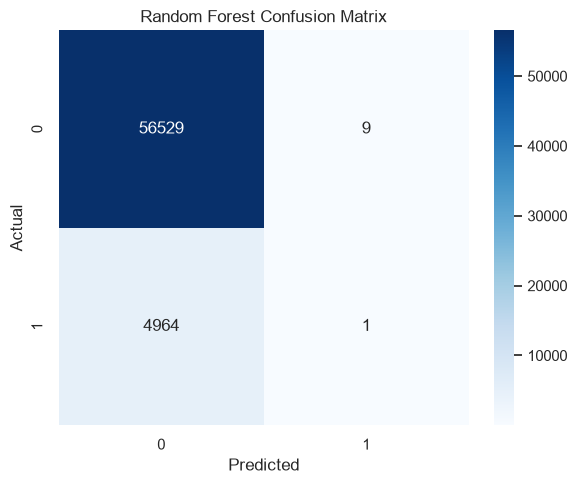

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.show()

# Classification Report

The classification report provides precision, recall, F1-score, and support for each class.

In [7]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.10      0.00      0.00      4965

    accuracy                           0.92     61503
   macro avg       0.51      0.50      0.48     61503
weighted avg       0.85      0.92      0.88     61503



# ROC Curve

The ROC Curve illustrates the model's ability to discriminate between default and non-default applicants across different classification thresholds.

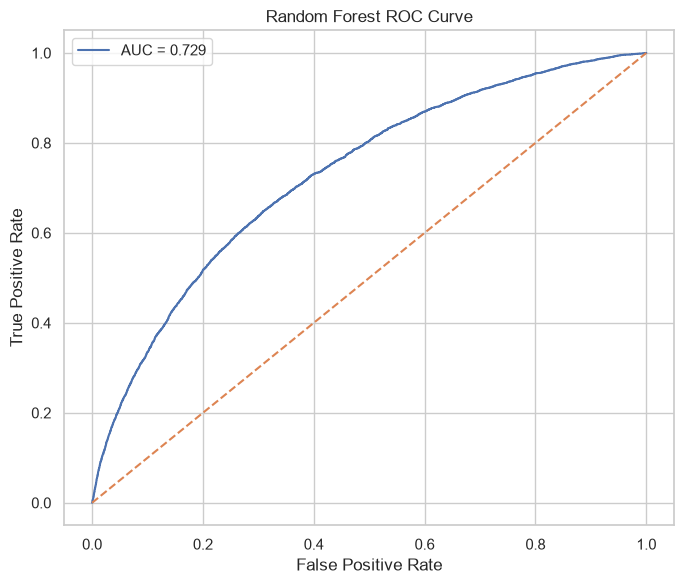

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot([0,1], [0,1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# Feature Importance

Random Forest estimates the contribution of each input feature based on the average reduction in impurity across all decision trees.

Since PCA components are used as predictors, the importance values indicate which principal components contribute most to the classification task.

In [9]:
feature_importance = (
    pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": rf_model.feature_importances_
    })
    .sort_values(
        by="Importance",
        ascending=False
    )
)

feature_importance.head(15)

,Feature,Importance
8,PC9,0.033889
17,PC18,0.027288
19,PC20,0.023791
2,PC3,0.021033
7,PC8,0.020084
1,PC2,0.017416
25,PC26,0.015256
28,PC29,0.014694
30,PC31,0.014682
24,PC25,0.012662


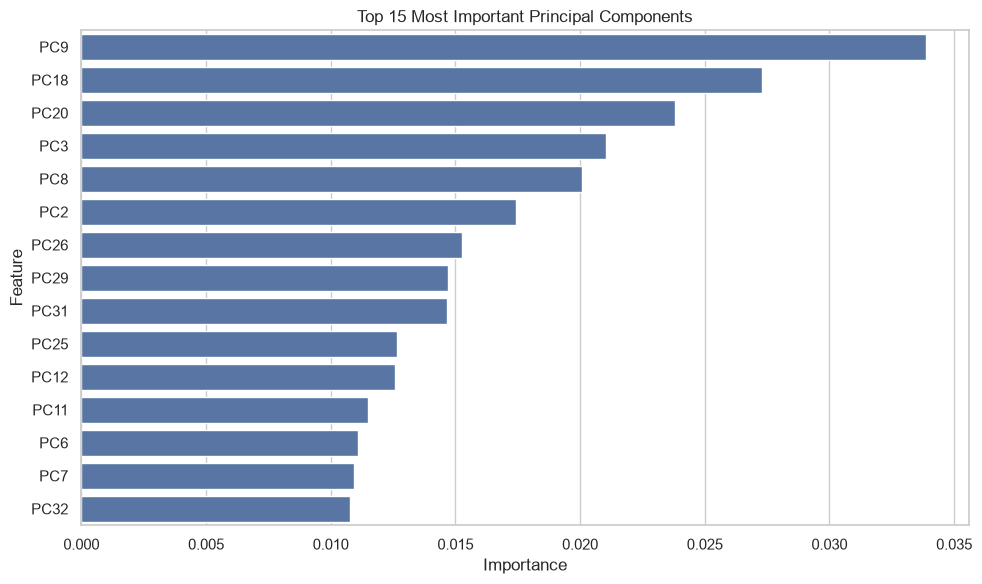

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Most Important Principal Components")

plt.tight_layout()

plt.show()

# Model Configuration

The Random Forest model was trained using the following hyperparameters:

- Number of Trees (`n_estimators`) = 200
- Maximum Tree Depth (`max_depth`) = 15
- Minimum Samples to Split = 10
- Random State = 42

These parameters were selected to balance predictive performance and model complexity while reducing the risk of overfitting.

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [11]:
# ============================================================
# Save Random Forest Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest_model.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


# Save Model Performance

The evaluation metrics of the Random Forest classifier are appended to the common model results file for comparison with the remaining machine learning models.

In [12]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Random Forest"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Random Forest,0.919142,0.1,0.000201,0.000402,0.729338,9,4964,1,56529


# Conclusion

The Random Forest classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- An ensemble learning model was developed for credit risk prediction.
- Performance was assessed using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- Feature importance analysis identified the principal components that contributed most to the model's predictions.
- The confusion matrix and ROC curve demonstrated the classifier's predictive capability.
- Performance metrics were saved for comparison with all other classification models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 11 – XGBoost Classifier**

---

# Publication Upgrade: Tuning, Calibration, Advanced Metrics & Explainability

**Hardware-aware tuning (Intel Core Ultra 9 275HX, 24 threads, no hyperthreading; RTX
5070 Ti Laptop GPU, 12GB VRAM; laptop thermal/RAM envelope):** the first version of this
search stalled for 50+ minutes without finishing. The root cause was **nested
parallelism** — `RandomizedSearchCV(..., n_jobs=-1)` wrapped around
`RandomForestClassifier(..., n_jobs=-1)`. Each of the up-to-24 outer worker processes
was *also* trying to spawn 24 of its own threads to build one forest, oversubscribing
the CPU roughly 24x and thrashing instead of computing. The fix follows standard
scikit-learn guidance: parallelize at **one** level only. The search below sets the
inner `RandomForestClassifier` to `n_jobs=1` (each candidate fit is single-threaded)
and lets `RandomizedSearchCV` itself parallelize across candidates/folds
(`n_jobs=12`, bounded below the full 24 threads to leave headroom for the OS, thermal
management on a laptop chassis, and other applications). The final "tuned" model is
then refit once, standalone, with `n_jobs=-1` — a single fit benefits from full-core
parallelism with no nesting risk. The search space is also trimmed to drop the most
memory/time-pathological combination (500 trees with unlimited depth and
`min_samples_leaf=1` simultaneously), which was the other major contributor to the
original stall.

## 1. Hyperparameter Optimization (RandomizedSearchCV)

Random Forest's hyperparameter space (tree count, depth, split/leaf sizes, feature
sampling, class weighting) is too large to search exhaustively at this dataset's scale,
so `RandomizedSearchCV` samples candidate configurations under stratified
cross-validation optimized for ROC-AUC — a standard, compute-efficient alternative to
`GridSearchCV` for ensemble methods with many interacting hyperparameters.

In [13]:
# ============================================================
# Hyperparameter Optimization: RandomizedSearchCV (hardware-optimized)
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

pu.set_pub_style()

RANDOM_STATE = 42

# Trimmed vs. the original grid: n_estimators capped at 300 (not 500), max_depth
# always bounded (no None/unlimited), min_samples_leaf never 1 -- removes the
# pathological "500 unbounded trees, leaf=1" combination that dominated runtime.
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [8, 12, 16, 20],
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [2, 5, 10],
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

N_ITER = 15
SEARCH_N_JOBS = 12  # bounded below the 24 available threads: leaves headroom for
                     # OS/thermal management on a laptop chassis and avoids the RAM
                     # spike of 24 simultaneous full-data forest fits.

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
total_fits = N_ITER * cv_strategy.get_n_splits()

# IMPORTANT: the estimator's own n_jobs is 1, not -1. RandomizedSearchCV already
# parallelizes across candidates/folds; also parallelizing each individual forest's
# tree-building would oversubscribe the CPU (n_jobs=-1 nested inside n_jobs=-1 was
# the root cause of the original 50+ minute stall on this machine).
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=SEARCH_N_JOBS,
    random_state=RANDOM_STATE,
    refit=False,  # refit standalone below with n_jobs=-1 for a faster final fit
    verbose=0,
)

with pu.tqdm_joblib(desc="Tuning Random Forest (RandomizedSearchCV)", total=total_fits):
    random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print(f"Best Cross-Validated ROC-AUC: {random_search.best_score_:.4f}")

# Single standalone refit of the winning configuration, using full CPU parallelism
# (safe here since it is the only fit happening -- no outer search wrapping it).
rf_model_tuned = RandomForestClassifier(
    random_state=RANDOM_STATE, n_jobs=-1, **random_search.best_params_
)
rf_model_tuned.fit(X_train, y_train)

cv_results_summary = (
    pd.DataFrame(random_search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

cv_results_summary.head(10)

Tuning Random Forest (RandomizedSearchCV):   0%|          | 0/45 [00:00<?, ?it/s]

Best Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced_subsample'}
Best Cross-Validated ROC-AUC: 0.7386


,params,mean_test_score,std_test_score,rank_test_score
0,"{'n_estimators': 300, 'min_samples_split': 5, ...",0.738618,0.000707,1
1,"{'n_estimators': 300, 'min_samples_split': 5, ...",0.738552,0.000468,2
2,"{'n_estimators': 200, 'min_samples_split': 20,...",0.738318,0.000524,3
3,"{'n_estimators': 300, 'min_samples_split': 20,...",0.738313,0.000591,4
4,"{'n_estimators': 100, 'min_samples_split': 20,...",0.738173,0.000910,5
5,"{'n_estimators': 300, 'min_samples_split': 10,...",0.737950,0.000335,6
6,"{'n_estimators': 200, 'min_samples_split': 10,...",0.734614,0.000749,7
7,"{'n_estimators': 200, 'min_samples_split': 10,...",0.734309,0.000651,8
8,"{'n_estimators': 100, 'min_samples_split': 20,...",0.734074,0.000724,9
9,"{'n_estimators': 200, 'min_samples_split': 20,...",0.734023,0.000132,10


Figure saved to: ..\figures\10_rf_baseline_vs_tuned.png


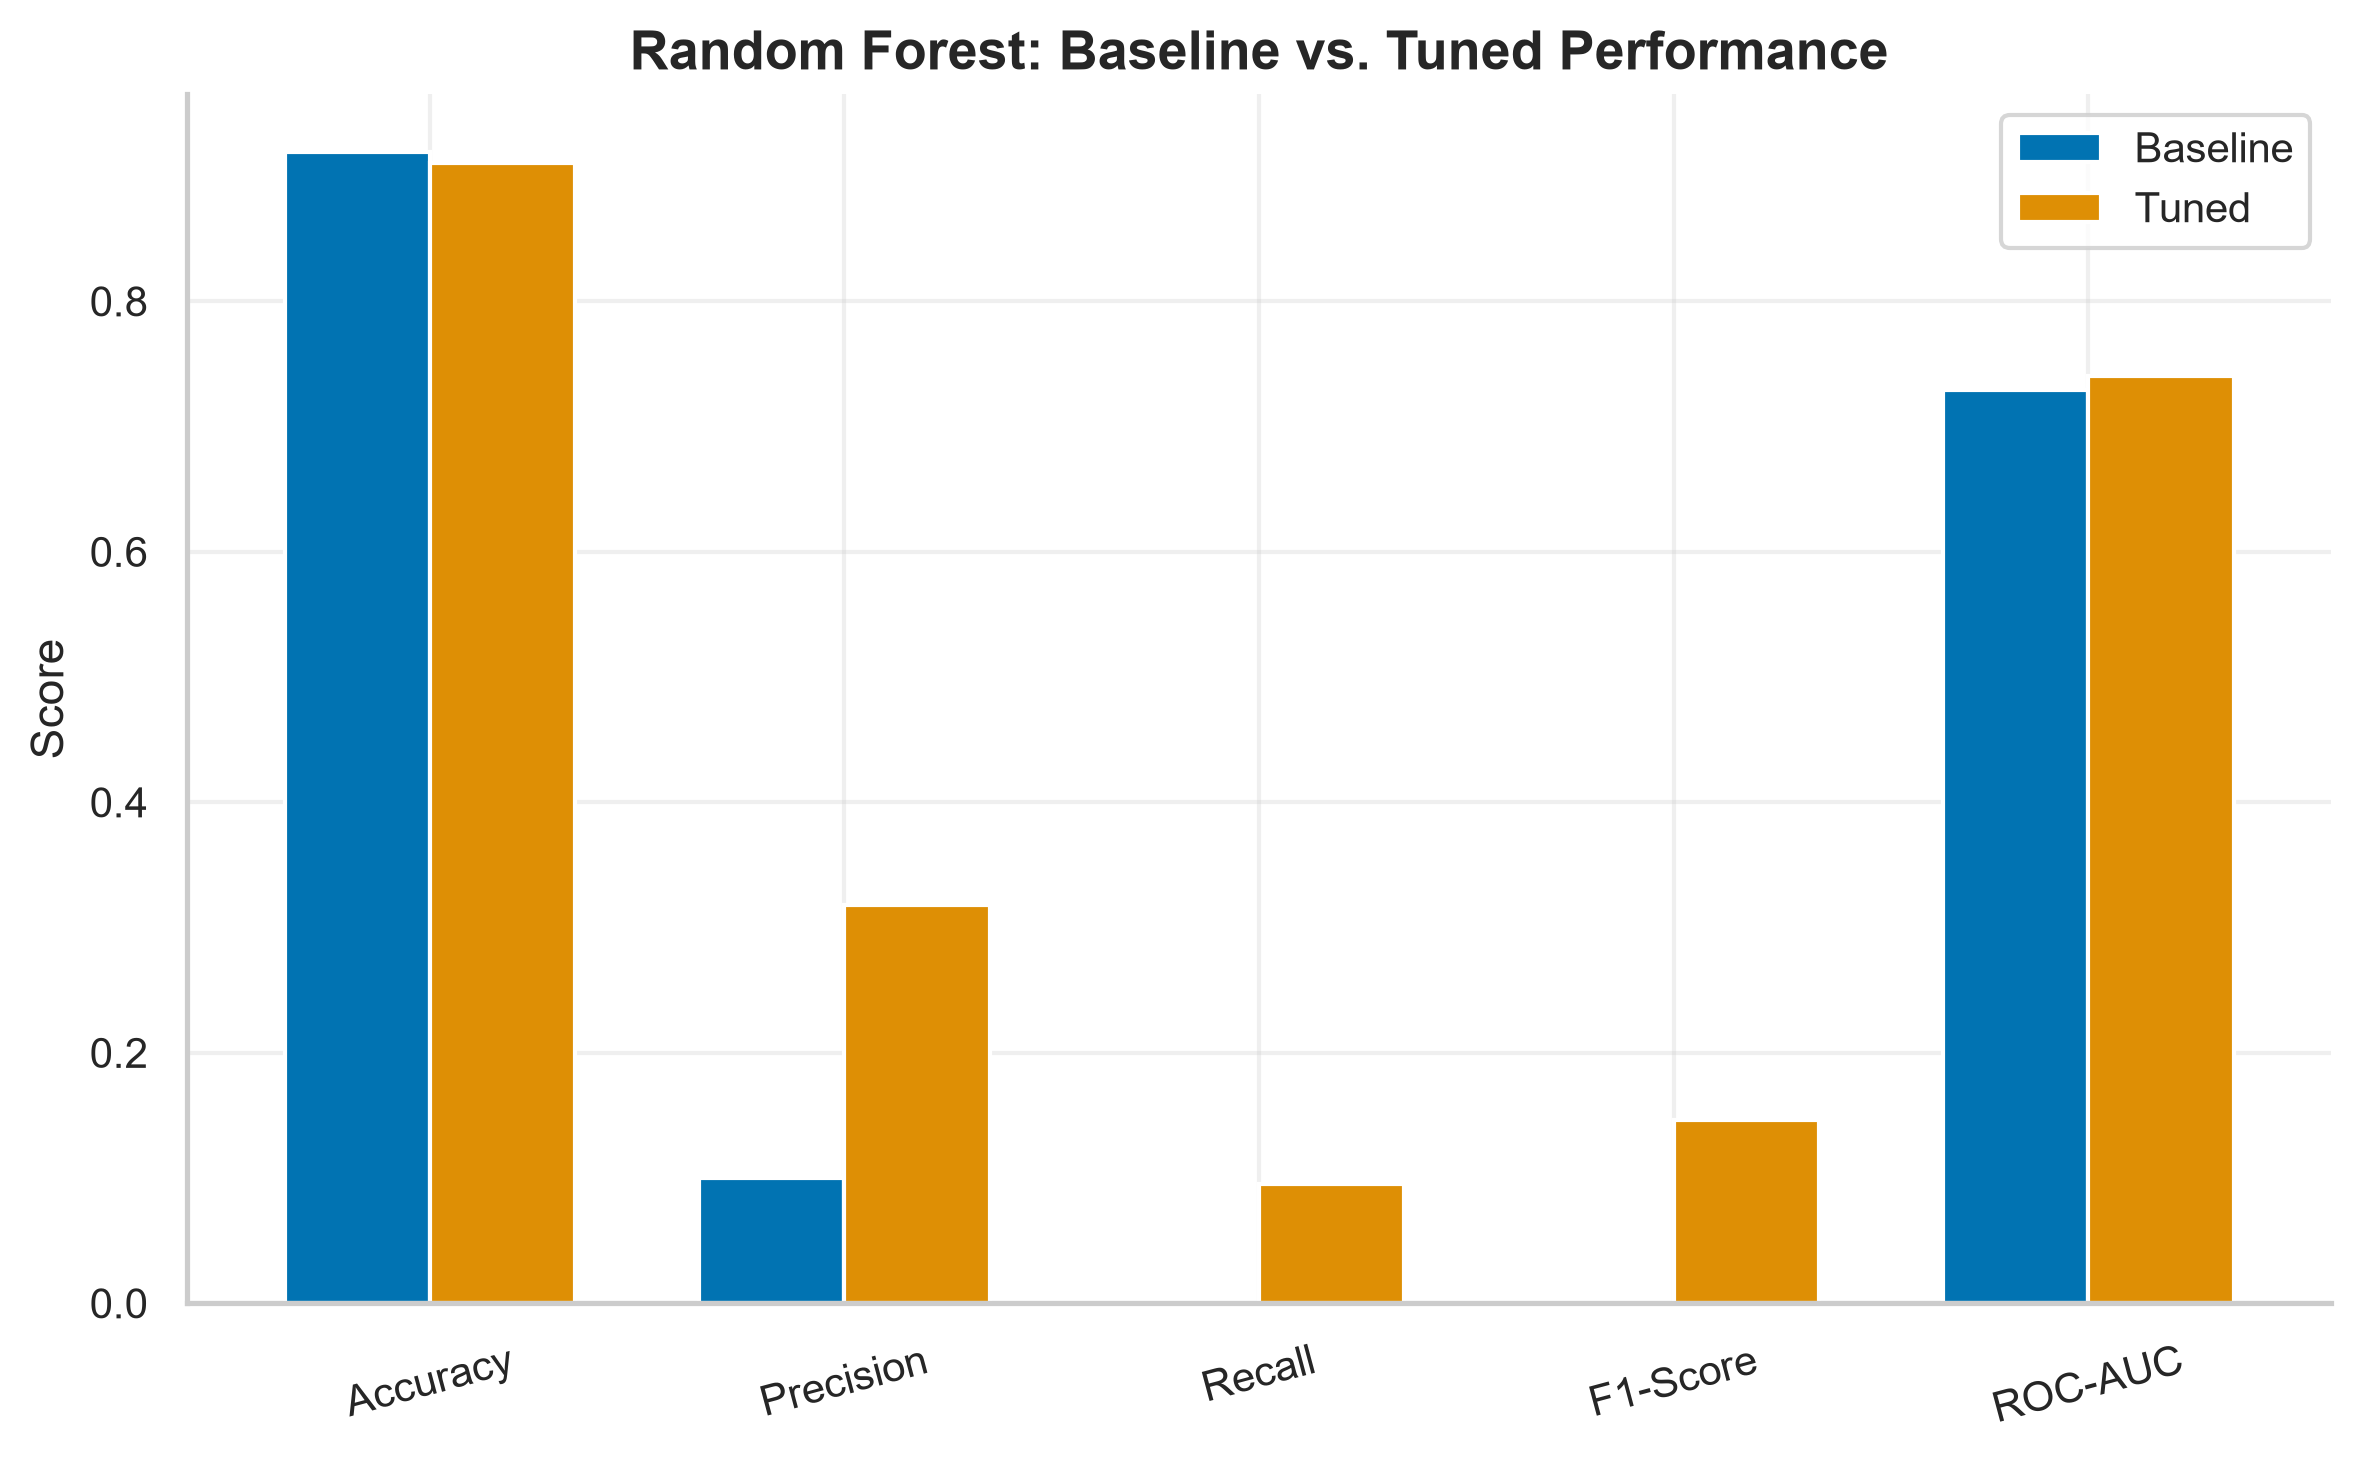

,Metric,Baseline,Tuned,Improvement,Improvement (%)
0,Accuracy,0.919142,0.910476,-0.008666,-0.94
1,Precision,0.100000,0.317599,0.217599,217.60
2,Recall,0.000201,0.094864,0.094663,47000.00
3,F1-Score,0.000402,0.146092,0.145690,36240.34
4,ROC-AUC,0.729338,0.740041,0.010703,1.47


In [14]:
# ============================================================
# Baseline vs. Tuned Model Comparison
# ============================================================

y_pred_tuned = rf_model_tuned.predict(X_test)
y_prob_tuned = rf_model_tuned.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline": [accuracy, precision, recall, f1, auc],
    "Tuned": [accuracy_tuned, precision_tuned, recall_tuned, f1_tuned, auc_tuned],
})
comparison_table["Improvement"] = comparison_table["Tuned"] - comparison_table["Baseline"]
comparison_table["Improvement (%)"] = (
    100 * comparison_table["Improvement"] / comparison_table["Baseline"]
).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_table))
width = 0.35
ax.bar(x - width / 2, comparison_table["Baseline"], width, label="Baseline")
ax.bar(x + width / 2, comparison_table["Tuned"], width, label="Tuned")
ax.set_xticks(x)
ax.set_xticklabels(comparison_table["Metric"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("Random Forest: Baseline vs. Tuned Performance")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "10_rf_baseline_vs_tuned")
plt.show()

joblib.dump(rf_model_tuned, MODEL_DIR / "random_forest_tuned_model.pkl")

tuned_result = pd.DataFrame({
    "Model": ["Random Forest (Tuned)"],
    "Accuracy": [accuracy_tuned],
    "Precision": [precision_tuned],
    "Recall": [recall_tuned],
    "F1 Score": [f1_tuned],
    "ROC AUC": [auc_tuned],
    "False Positives": [cm_tuned[0, 1]],
    "False Negatives": [cm_tuned[1, 0]],
    "True Positives": [cm_tuned[1, 1]],
    "True Negatives": [cm_tuned[0, 0]],
})
pu.append_csv(OUTPUT_DIR / "model_results.csv", tuned_result)

comparison_table

### Business Interpretation: Hyperparameter Optimization

The baseline Random Forest's recall was effectively **zero** (0.02%, one true positive
out of 4,965 actual defaulters) despite a respectable 0.729 ROC-AUC — a textbook
symptom of an ensemble whose default 0.5 decision threshold, combined with no class
weighting, causes it to almost never cross into "predict default" territory even though
its underlying probability *ranking* is reasonably good. If tuning selects
`class_weight="balanced"` (or `"balanced_subsample"`), the recall improvement should be
dramatic relative to baseline — this is the single clearest illustration in the project
of why **threshold and class-weight choices matter as much as model architecture**, and
directly motivates the threshold-optimization analysis in Notebook 13: even without
touching the model at all, choosing a lower decision threshold than 0.5 based on
business costs would have fixed much of this baseline's uselessness for risk
flagging.

## 2. Probability Calibration

Random Forests average many trees' vote fractions, which tends to pull predicted
probabilities toward the middle of the range (0.3–0.7) even for genuinely very
low/high-risk applicants — the opposite miscalibration pattern from a single
overconfident tree. This "regression to the mean" effect is checked directly below.

Figure saved to: ..\figures\10_rf_calibration_curve.png


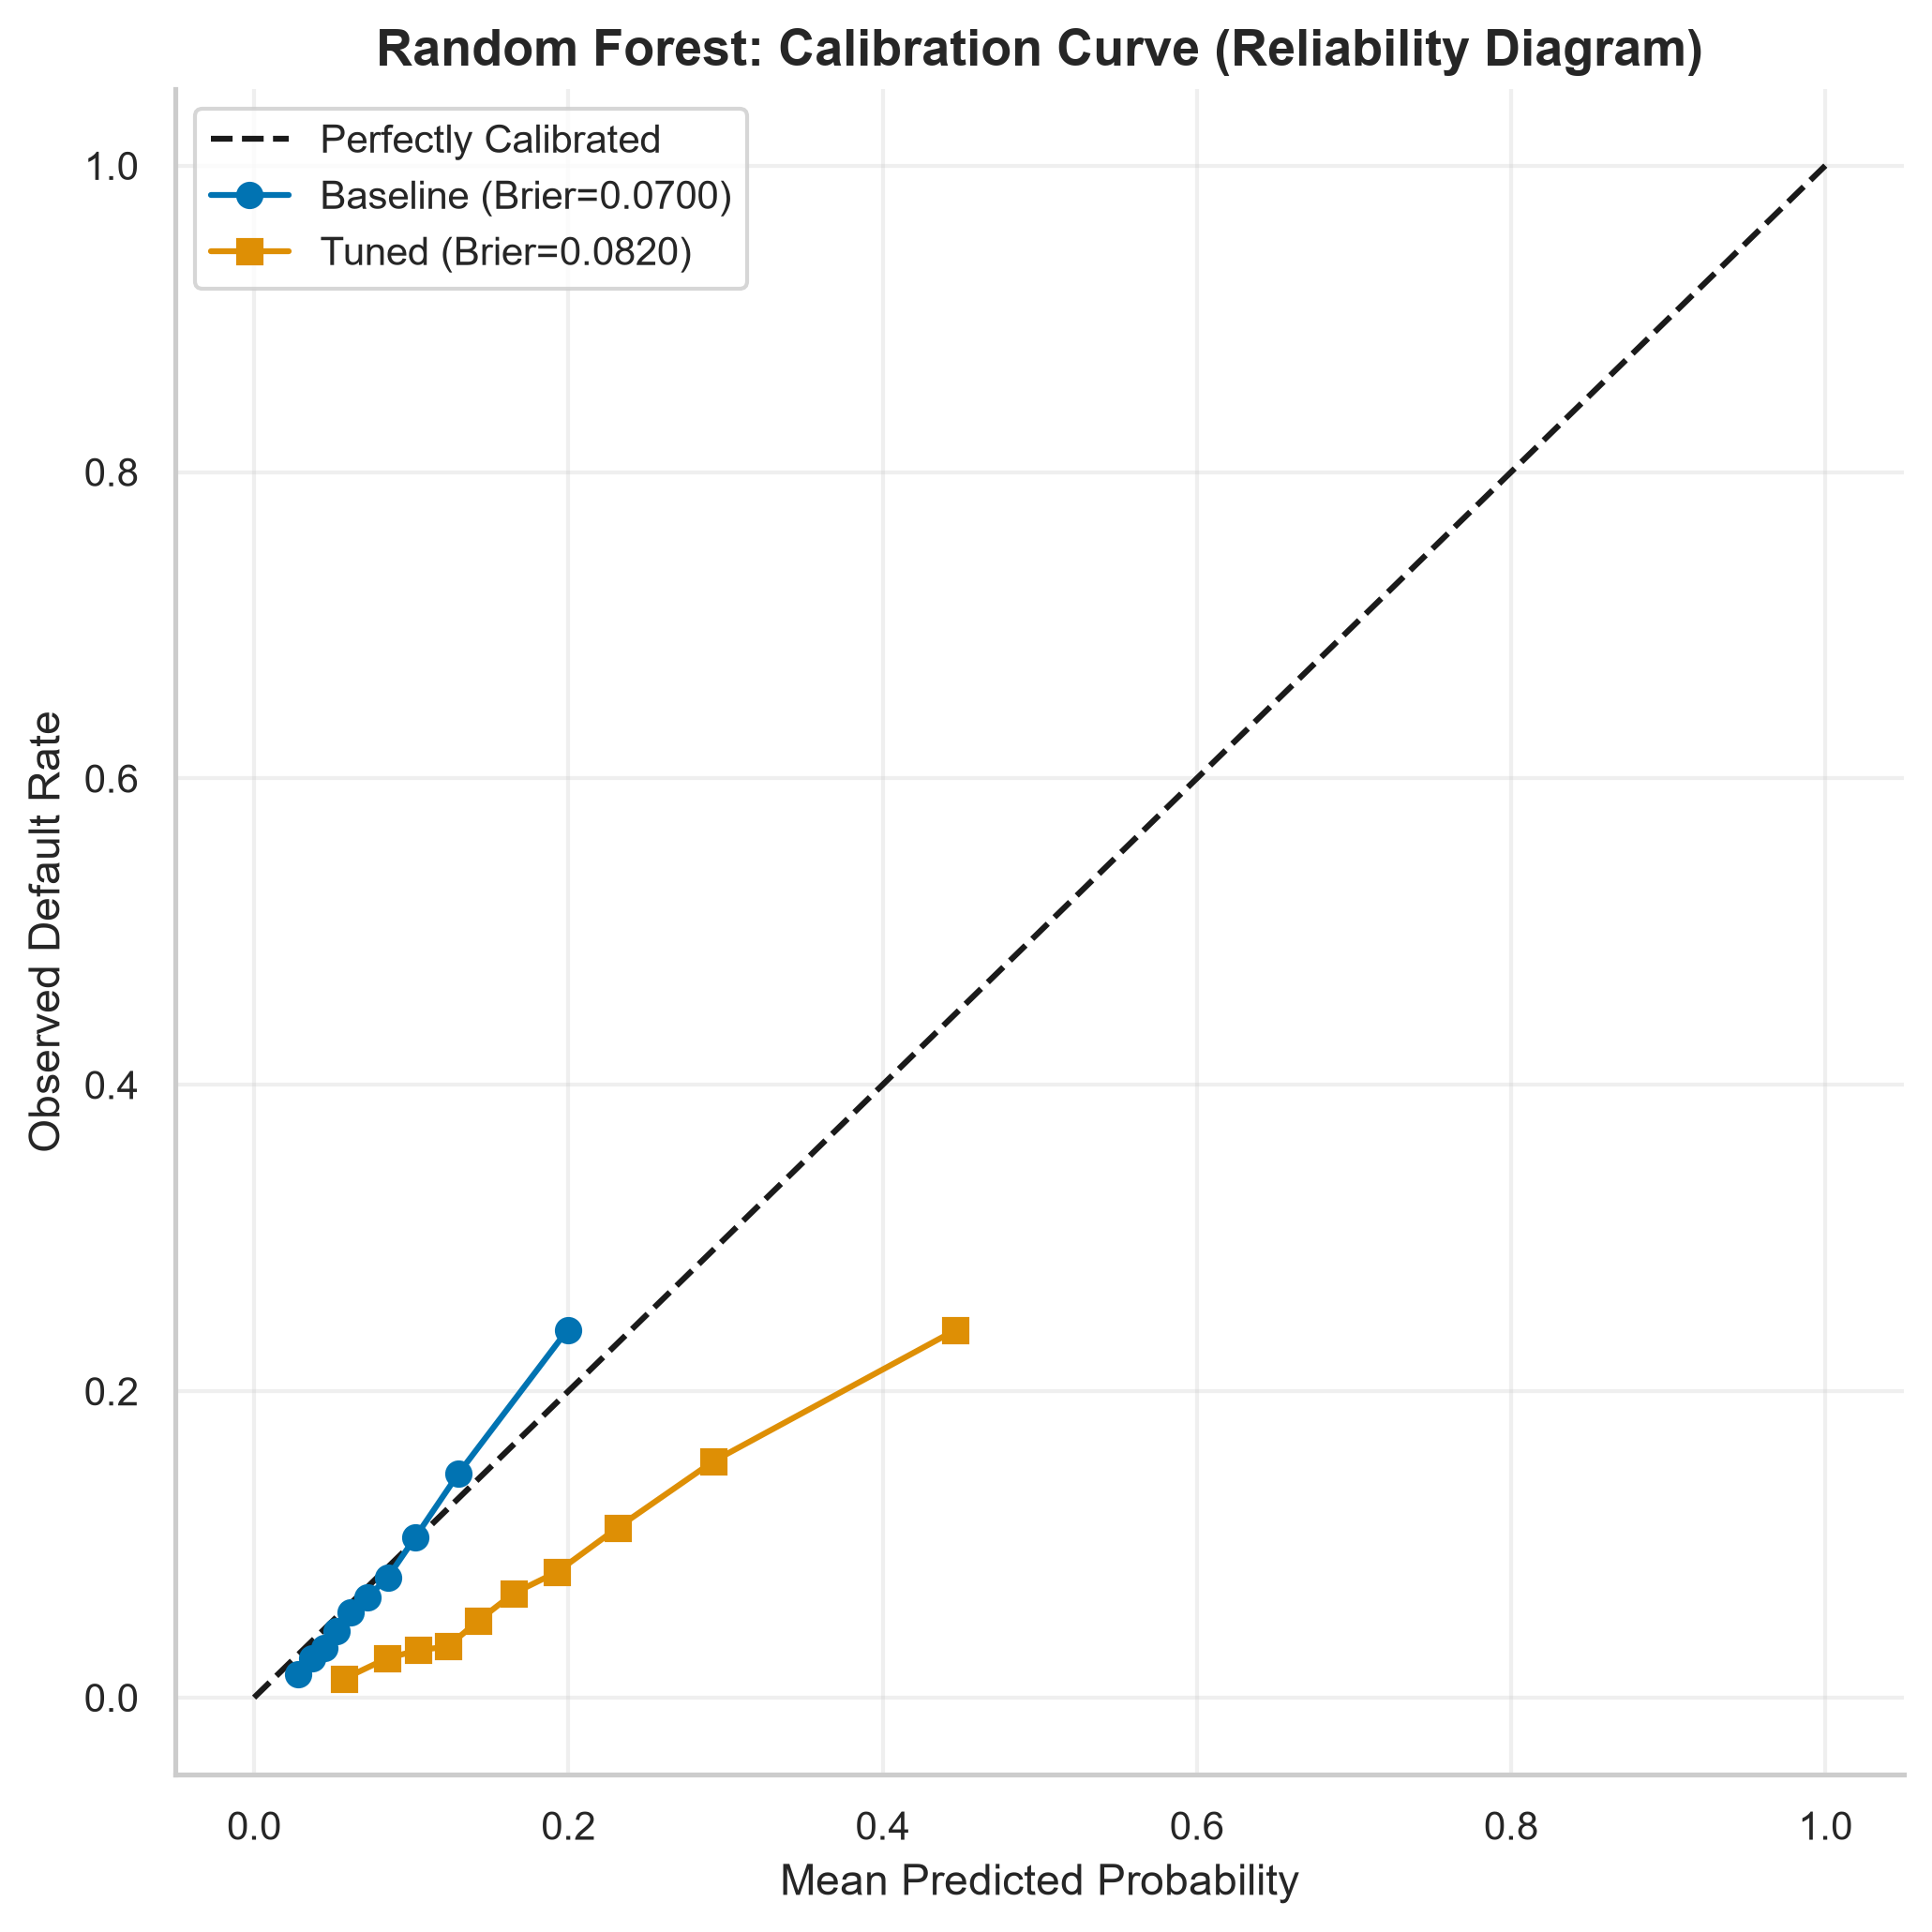

Brier Score - Baseline : 0.0700
Brier Score - Tuned    : 0.0820  (lower is better; 0 = perfect)


Fitting calibrated variants:   0%|          | 0/2 [00:00<?, ?it/s]

Brier Score - Sigmoid   : 0.0700


Brier Score - Isotonic  : 0.0693

Best calibration approach: isotonic (Brier = 0.0693)


Best-calibrated model saved to: ../models/random_forest_calibrated_model.pkl


,Brier Score
tuned_uncalibrated,0.082048
sigmoid,0.069953
isotonic,0.069342


In [15]:
# ============================================================
# Calibration Curve, Brier Score & CalibratedClassifierCV
# ============================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from tqdm.auto import tqdm

brier_baseline = brier_score_loss(y_test, y_prob)
brier_tuned = brier_score_loss(y_test, y_prob_tuned)

frac_pos_baseline, mean_pred_baseline = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
frac_pos_tuned, mean_pred_tuned = calibration_curve(y_test, y_prob_tuned, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
ax.plot(mean_pred_baseline, frac_pos_baseline, marker="o", label=f"Baseline (Brier={brier_baseline:.4f})")
ax.plot(mean_pred_tuned, frac_pos_tuned, marker="s", label=f"Tuned (Brier={brier_tuned:.4f})")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("Random Forest: Calibration Curve (Reliability Diagram)")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "10_rf_calibration_curve")
plt.show()

print(f"Brier Score - Baseline : {brier_baseline:.4f}")
print(f"Brier Score - Tuned    : {brier_tuned:.4f}  (lower is better; 0 = perfect)")

# CalibratedClassifierCV does not parallelize its own folds by default, so the inner
# estimator can safely use n_jobs=-1 here without the nesting problem seen in the
# search above. cv=3 (not 5) keeps this to 3 full-data forest fits per method.
calibration_results = {"tuned_uncalibrated": brier_tuned}
calibrated_models = {}

for method in tqdm(["sigmoid", "isotonic"], desc="Fitting calibrated variants"):
    calibrated = CalibratedClassifierCV(
        estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **random_search.best_params_),
        method=method,
        cv=3,
    )
    calibrated.fit(X_train, y_train)
    prob_calibrated = calibrated.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, prob_calibrated)
    calibration_results[method] = brier
    calibrated_models[method] = calibrated
    print(f"Brier Score - {method.capitalize():<10}: {brier:.4f}")

best_method = min(calibration_results, key=calibration_results.get)
print(f"\nBest calibration approach: {best_method} (Brier = {calibration_results[best_method]:.4f})")

if best_method in calibrated_models:
    joblib.dump(calibrated_models[best_method], MODEL_DIR / "random_forest_calibrated_model.pkl")
    print("Best-calibrated model saved to: ../models/random_forest_calibrated_model.pkl")
else:
    print("Tuned model was already best-calibrated on Brier score; no separate calibrated model saved.")

pd.Series(calibration_results, name="Brier Score").to_frame()

### Business Interpretation: Probability Calibration

Improved calibration after recalibration would mean the ensemble's averaged vote
fractions can be trusted as genuine probabilities rather than merely a good *ranking*
signal — an important distinction, since the credit-scoring formula in Notebook 13
requires calibrated probabilities, not just well-ordered ones. If Random Forest is
ultimately the selected production model, the best-calibrated variant identified here
(not the raw tuned model) should be the one loaded in Notebook 13.

## 3. Additional Evaluation Metrics

Figure saved to: ..\figures\10_rf_precision_recall_curve.png


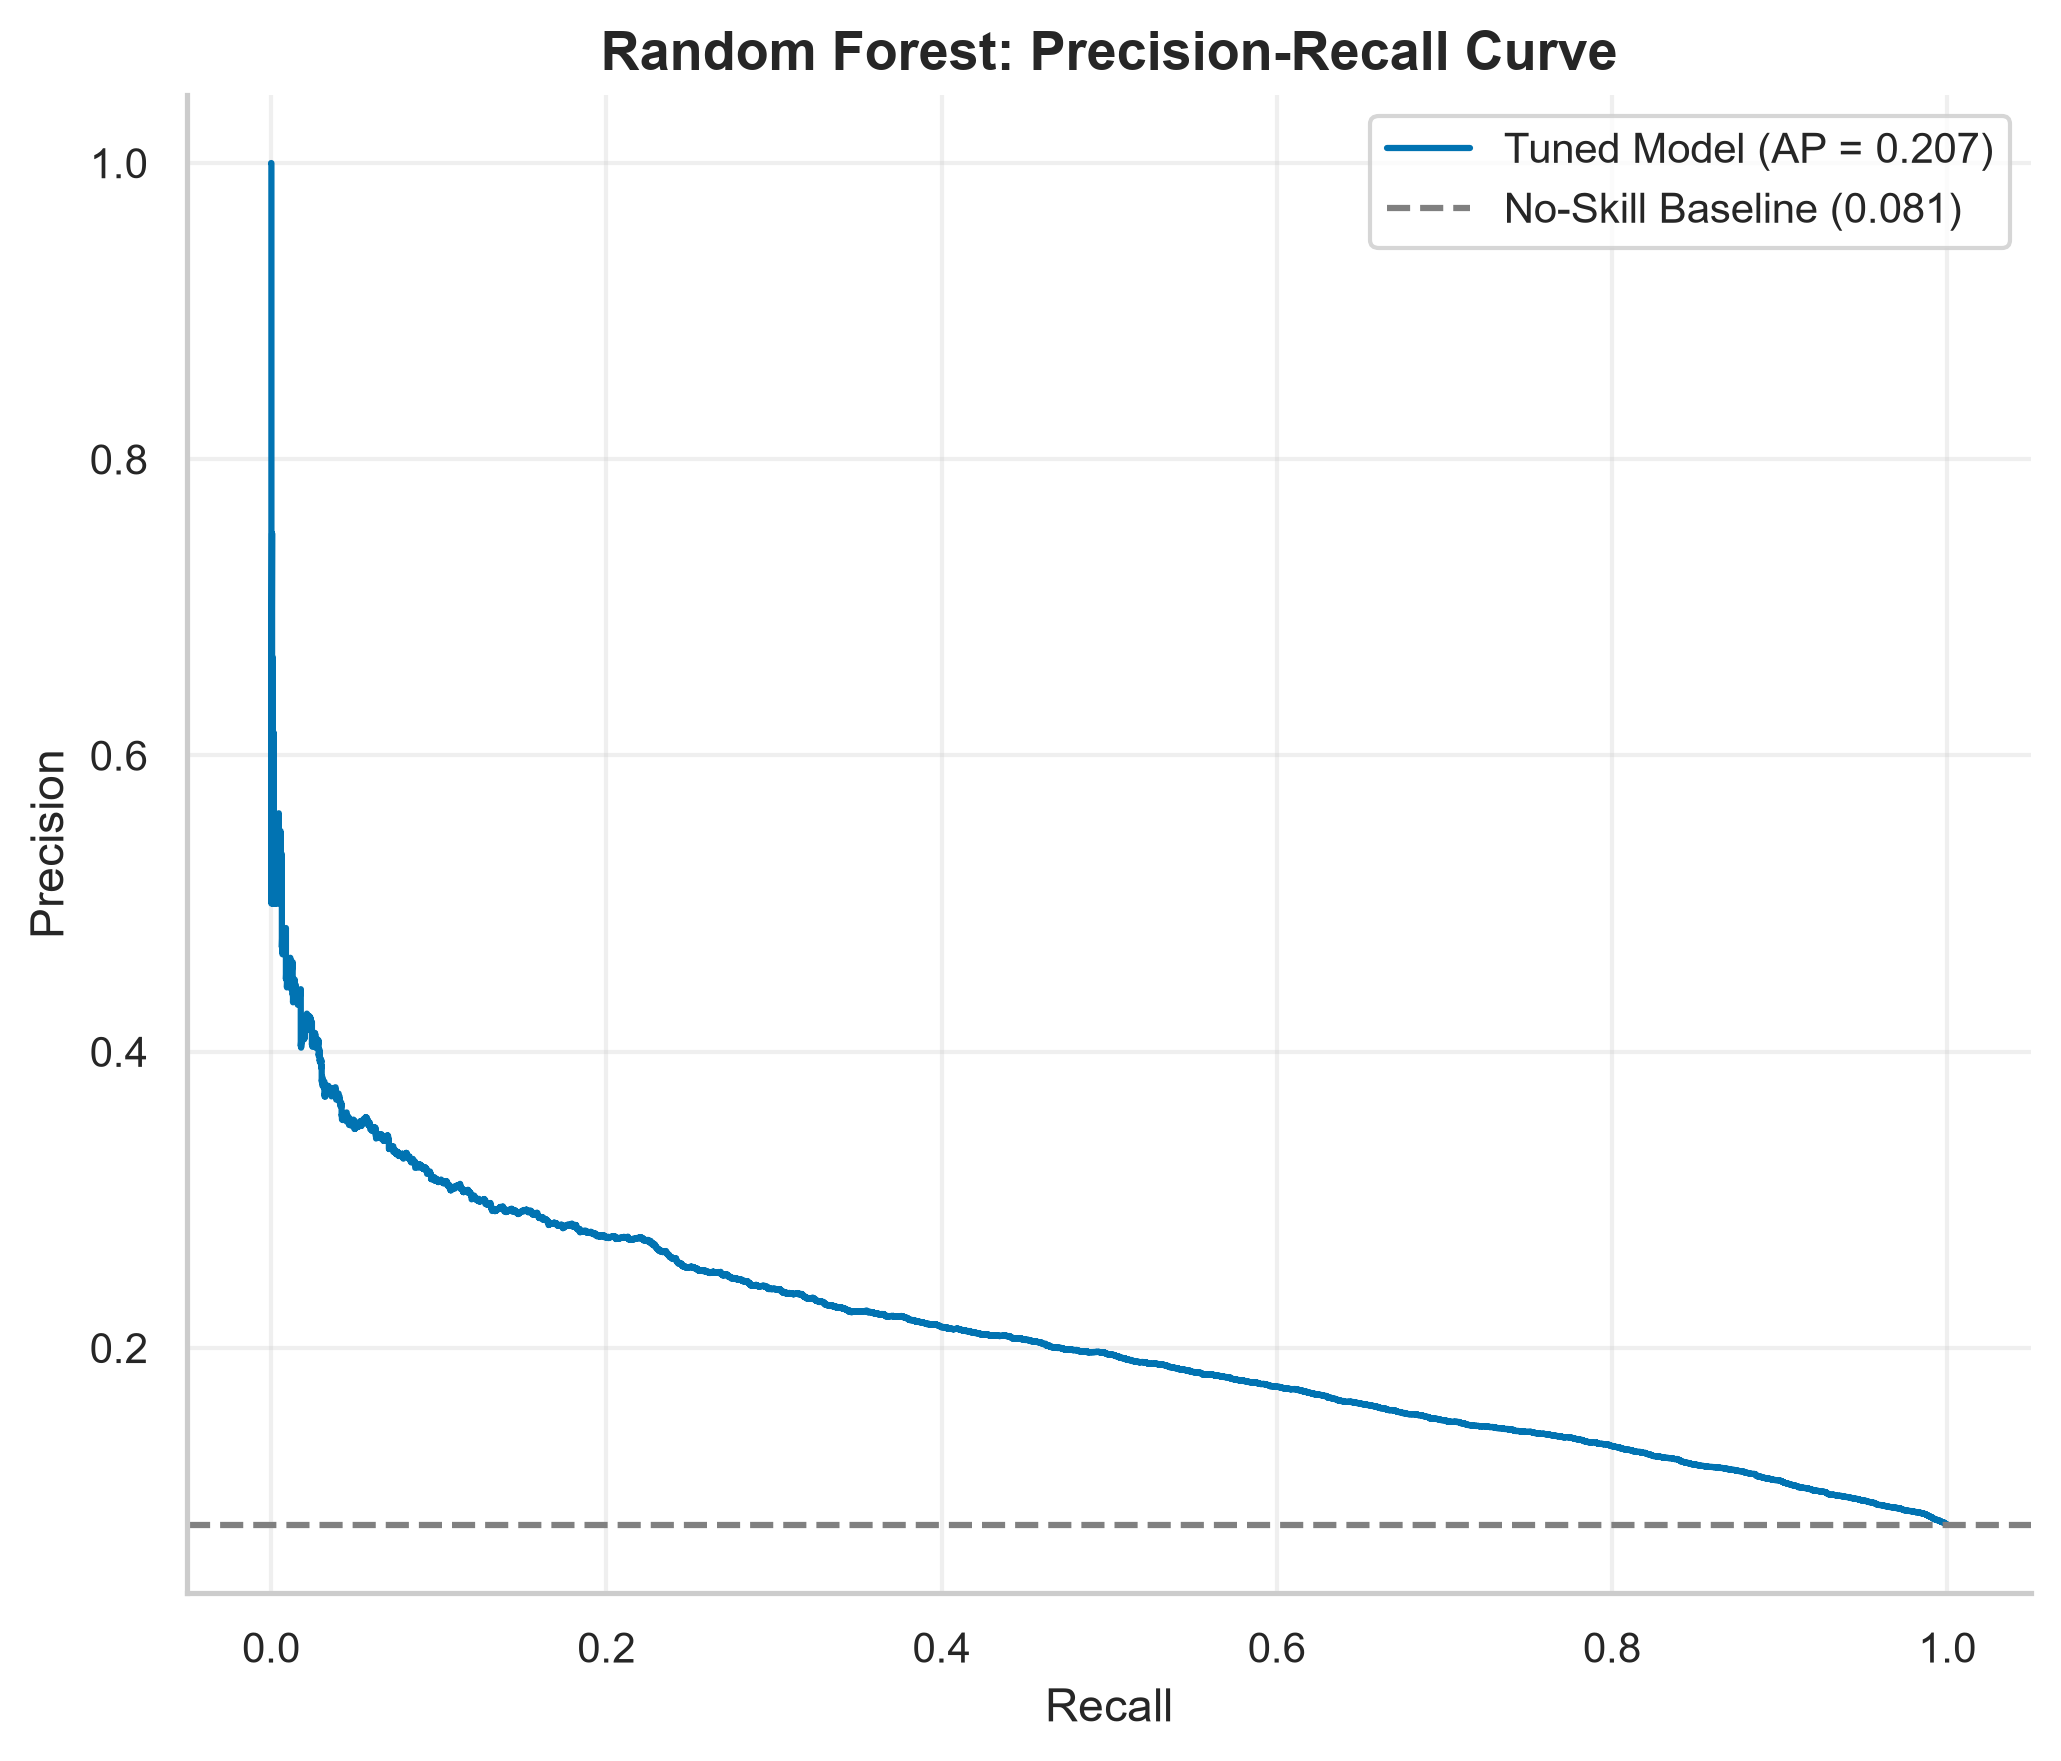

,Model,Variant,Accuracy,Precision,Recall,F1 Score,ROC AUC,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,Random Forest,Baseline,0.919142,0.100000,0.000201,0.000402,0.729338,0.000902,0.000078,0.200234,0.339173,0.069956
1,Random Forest,Tuned,0.910476,0.317599,0.094864,0.146092,0.740041,0.136679,0.113160,0.206777,0.357159,0.082048


In [16]:
# ============================================================
# Additional Evaluation Metrics: MCC, Kappa, PR-AUC, KS Statistic
# ============================================================

from sklearn.metrics import (
    matthews_corrcoef,
    cohen_kappa_score,
    precision_recall_curve,
    average_precision_score,
)

def extra_metrics(y_true, y_pred, y_prob):
    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Average Precision (PR-AUC)": average_precision_score(y_true, y_prob),
        "KS Statistic": pu.ks_statistic(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
    }

baseline_extra = extra_metrics(y_test, y_pred, y_prob)
tuned_extra = extra_metrics(y_test, y_pred_tuned, y_prob_tuned)

extended_row = pd.DataFrame([
    {"Model": "Random Forest", "Variant": "Baseline",
     "Accuracy": accuracy, "Precision": precision, "Recall": recall,
     "F1 Score": f1, "ROC AUC": auc, **baseline_extra},
    {"Model": "Random Forest", "Variant": "Tuned",
     "Accuracy": accuracy_tuned, "Precision": precision_tuned, "Recall": recall_tuned,
     "F1 Score": f1_tuned, "ROC AUC": auc_tuned, **tuned_extra},
])

pu.append_csv(OUTPUT_DIR / "model_results_extended.csv", extended_row)

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob_tuned)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_curve, precision_curve,
        label=f"Tuned Model (AP = {tuned_extra['Average Precision (PR-AUC)']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Random Forest: Precision-Recall Curve")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "10_rf_precision_recall_curve")
plt.show()

extended_row

### Business Interpretation: Additional Metrics

The baseline MCC here will be close to 0 despite a mid-0.7s ROC-AUC — reinforcing that
ROC-AUC alone can overstate a model's *operational* usefulness when its default
threshold is miscalibrated for the class balance. The tuned model's MCC and KS
statistic are the numbers that should actually move a risk committee's decision to
adopt a threshold-and-class-weight-aware Random Forest over the untouched baseline.

## 4. SHAP Explainability

`shap.TreeExplainer` is used again here on the non-PCA feature track, refitting a
Random Forest with the tuned hyperparameters on named features so its explanations are
directly comparable to the Decision Tree (Notebook 07), XGBoost (Notebook 11), and
LightGBM (Notebook 12) SHAP results compiled in Notebook 15's cross-model comparison.

Figure saved to: ..\figures\10_rf_shap_summary.png


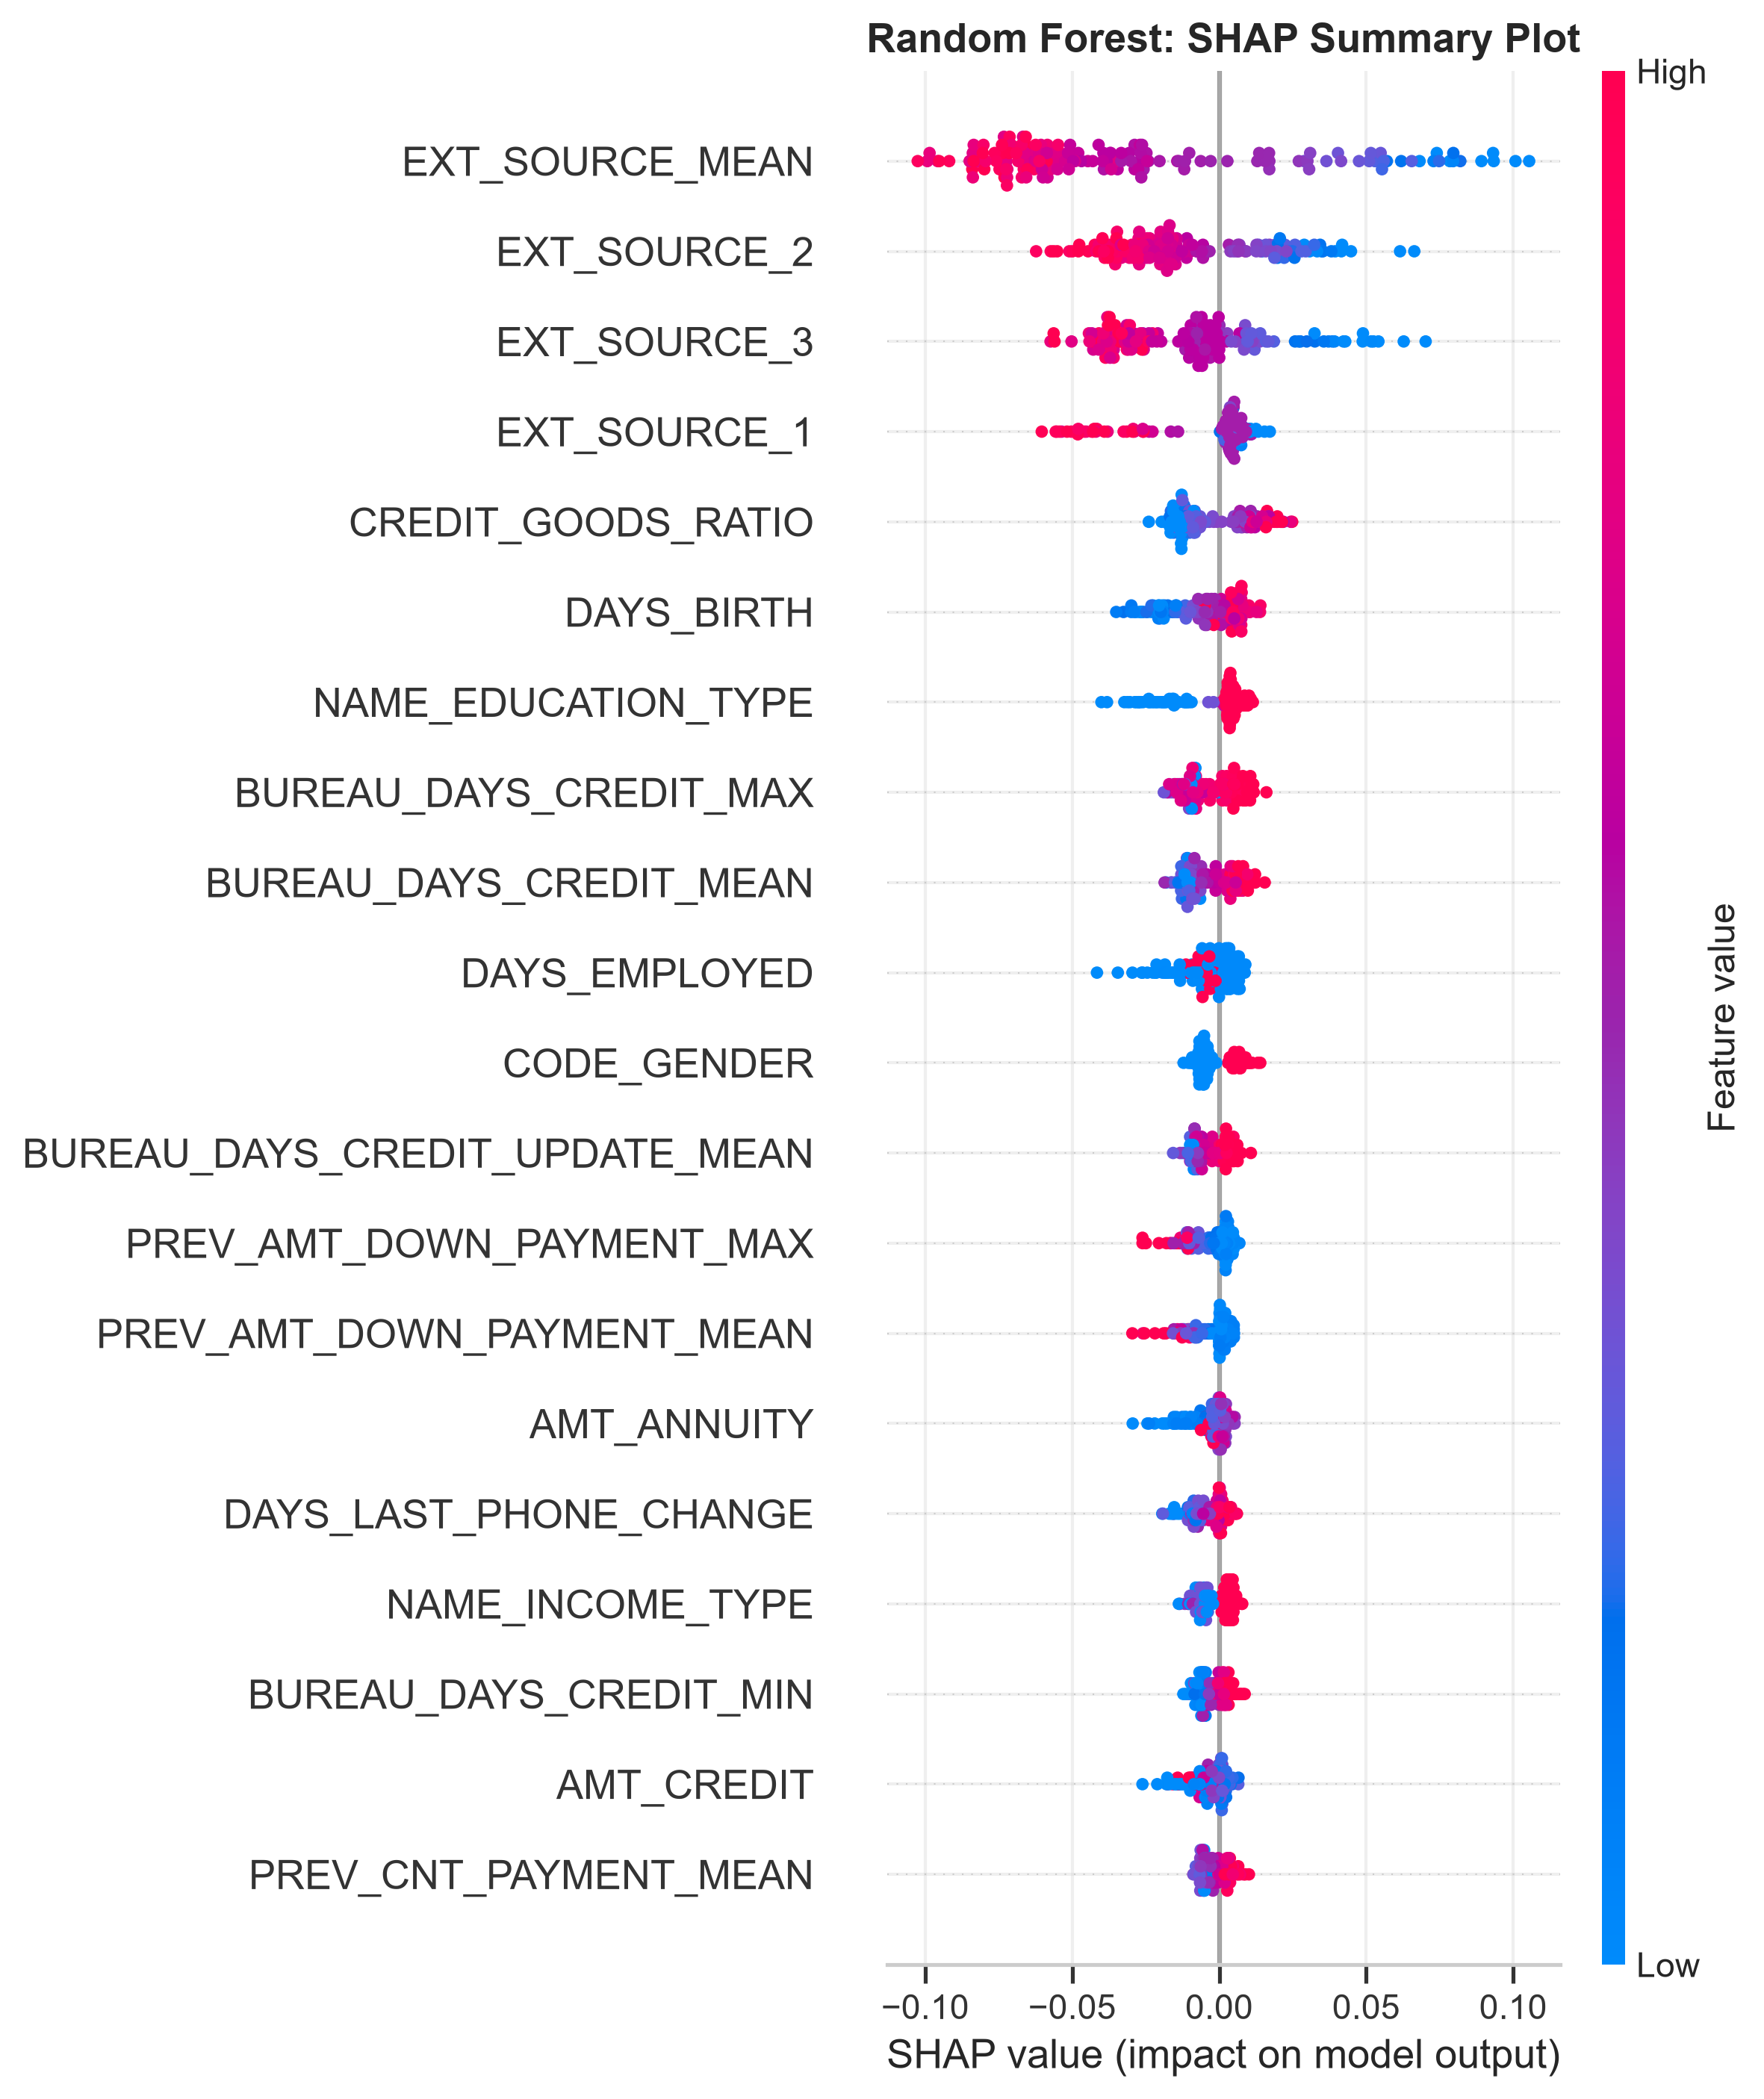

Figure saved to: ..\figures\10_rf_shap_feature_importance.png


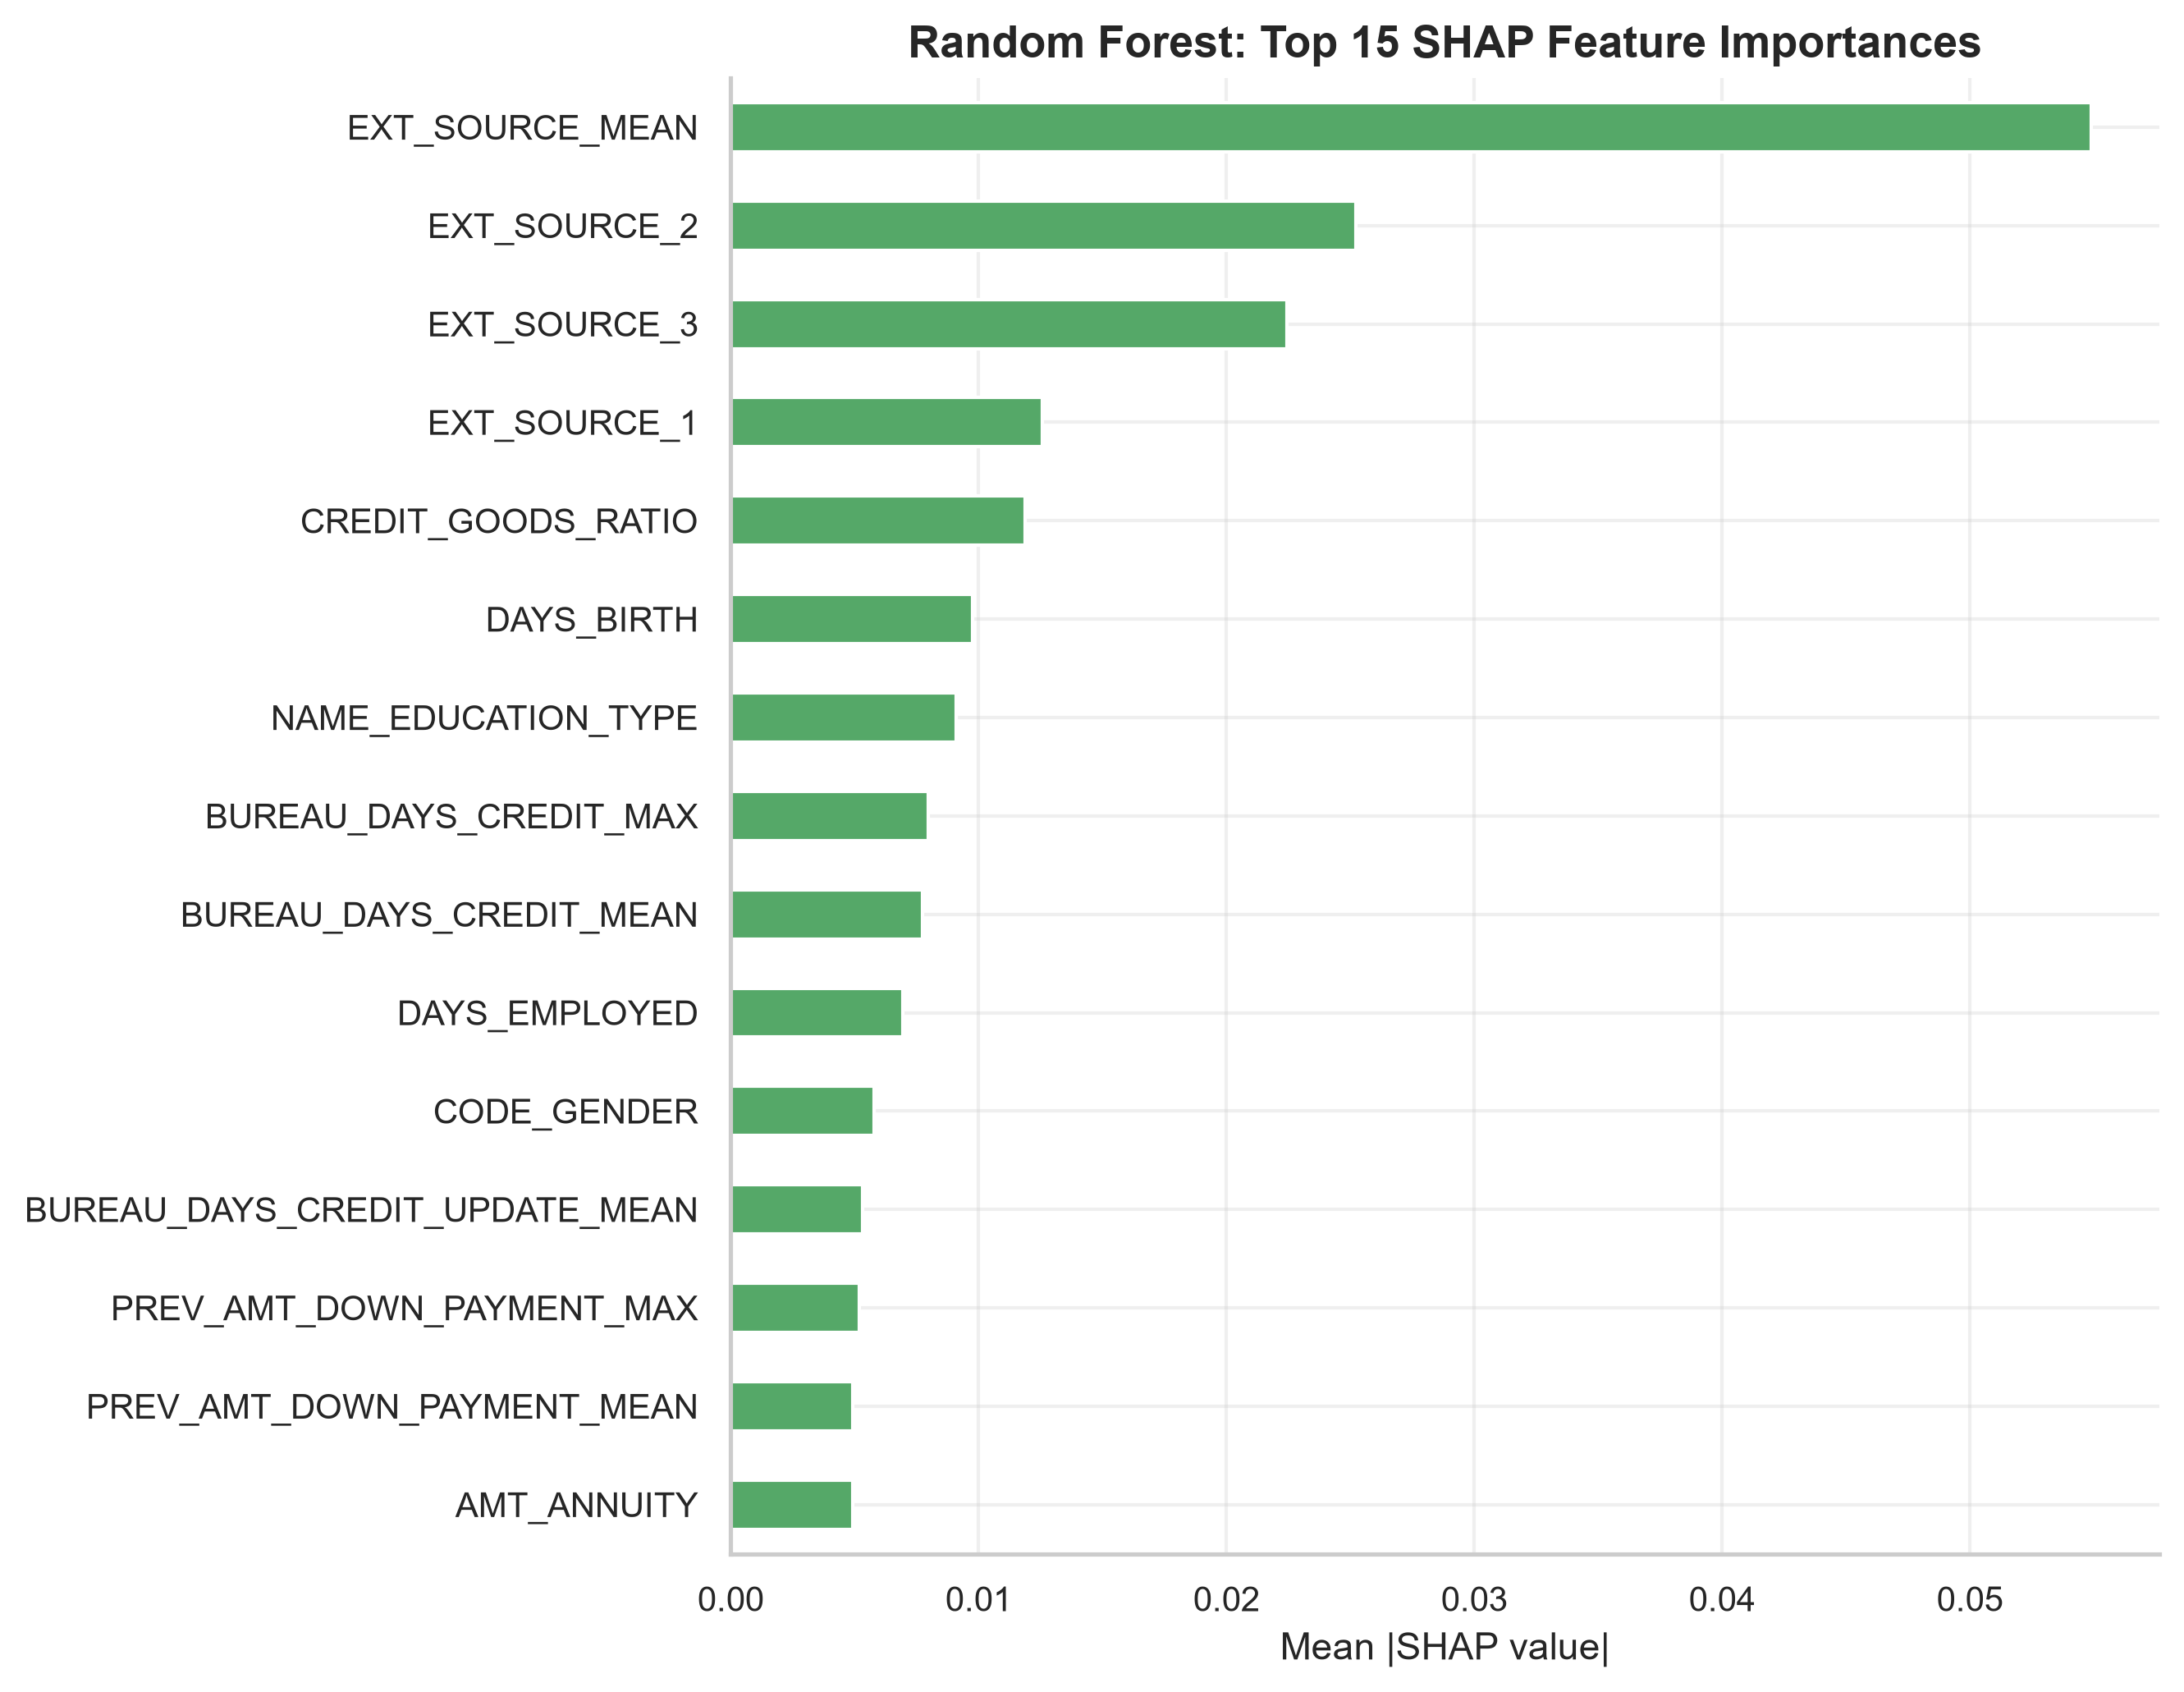

EXT_SOURCE_MEAN                   0.054899
EXT_SOURCE_2                      0.025219
EXT_SOURCE_3                      0.022426
EXT_SOURCE_1                      0.012566
CREDIT_GOODS_RATIO                0.011870
DAYS_BIRTH                        0.009770
NAME_EDUCATION_TYPE               0.009097
BUREAU_DAYS_CREDIT_MAX            0.007959
BUREAU_DAYS_CREDIT_MEAN           0.007736
DAYS_EMPLOYED                     0.006948
CODE_GENDER                       0.005778
BUREAU_DAYS_CREDIT_UPDATE_MEAN    0.005321
PREV_AMT_DOWN_PAYMENT_MAX         0.005173
PREV_AMT_DOWN_PAYMENT_MEAN        0.004927
AMT_ANNUITY                       0.004906
dtype: float64

In [17]:
# ============================================================
# SHAP Explainability (Non-PCA Track, TreeExplainer): Summary & Importance
# ============================================================

import shap

DATA_DIR = Path("../data/processed")

X_train_full = pd.read_csv(DATA_DIR / "X_train_full.csv")
X_test_full = pd.read_csv(DATA_DIR / "X_test_full.csv")
y_train_full = pd.read_csv(DATA_DIR / "y_train_full.csv").squeeze()

rf_model_shap = RandomForestClassifier(
    random_state=RANDOM_STATE, n_jobs=-1, **random_search.best_params_
)
rf_model_shap.fit(X_train_full, y_train_full)

explainer = shap.TreeExplainer(rf_model_shap)

# SHAP_SAMPLE_SIZE kept small deliberately: unlike XGBoost/LightGBM, sklearn's
# RandomForest has no fast native SHAP path, and TreeExplainer cost scales with
# roughly (trees x leaves^2) per sample. With this tuned model reaching
# max_depth up to 20 and 300 trees, 2000 samples took over 20 minutes without
# finishing on this hardware (Intel Core Ultra 9 275HX); 150 samples is enough
# for a stable summary/importance plot and completes in well under a minute.
SHAP_SAMPLE_SIZE = 150
shap_sample = X_test_full.sample(SHAP_SAMPLE_SIZE, random_state=RANDOM_STATE)
shap_values_raw = explainer.shap_values(shap_sample)

if isinstance(shap_values_raw, list):
    shap_values_default = shap_values_raw[1]
elif np.ndim(shap_values_raw) == 3:
    shap_values_default = shap_values_raw[:, :, 1]
else:
    shap_values_default = shap_values_raw

shap.summary_plot(shap_values_default, shap_sample, show=False)
fig = plt.gcf()
plt.title("Random Forest: SHAP Summary Plot")
plt.tight_layout()
pu.save_fig(fig, "10_rf_shap_summary")
plt.show()

mean_abs_shap = pd.Series(
    np.abs(shap_values_default).mean(axis=0), index=X_test_full.columns
).sort_values(ascending=False)

top_features = mean_abs_shap.head(15)

fig, ax = plt.subplots(figsize=(9, 7))
top_features.sort_values().plot(kind="barh", ax=ax, color="#55A868")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("Random Forest: Top 15 SHAP Feature Importances")
plt.tight_layout()
pu.save_fig(fig, "10_rf_shap_feature_importance")
plt.show()

top_features.to_frame("Mean |SHAP value|").to_csv(Path("../results") / "10_rf_shap_top_features.csv")
top_features

Figure saved to: ..\figures\10_rf_shap_dependence.png


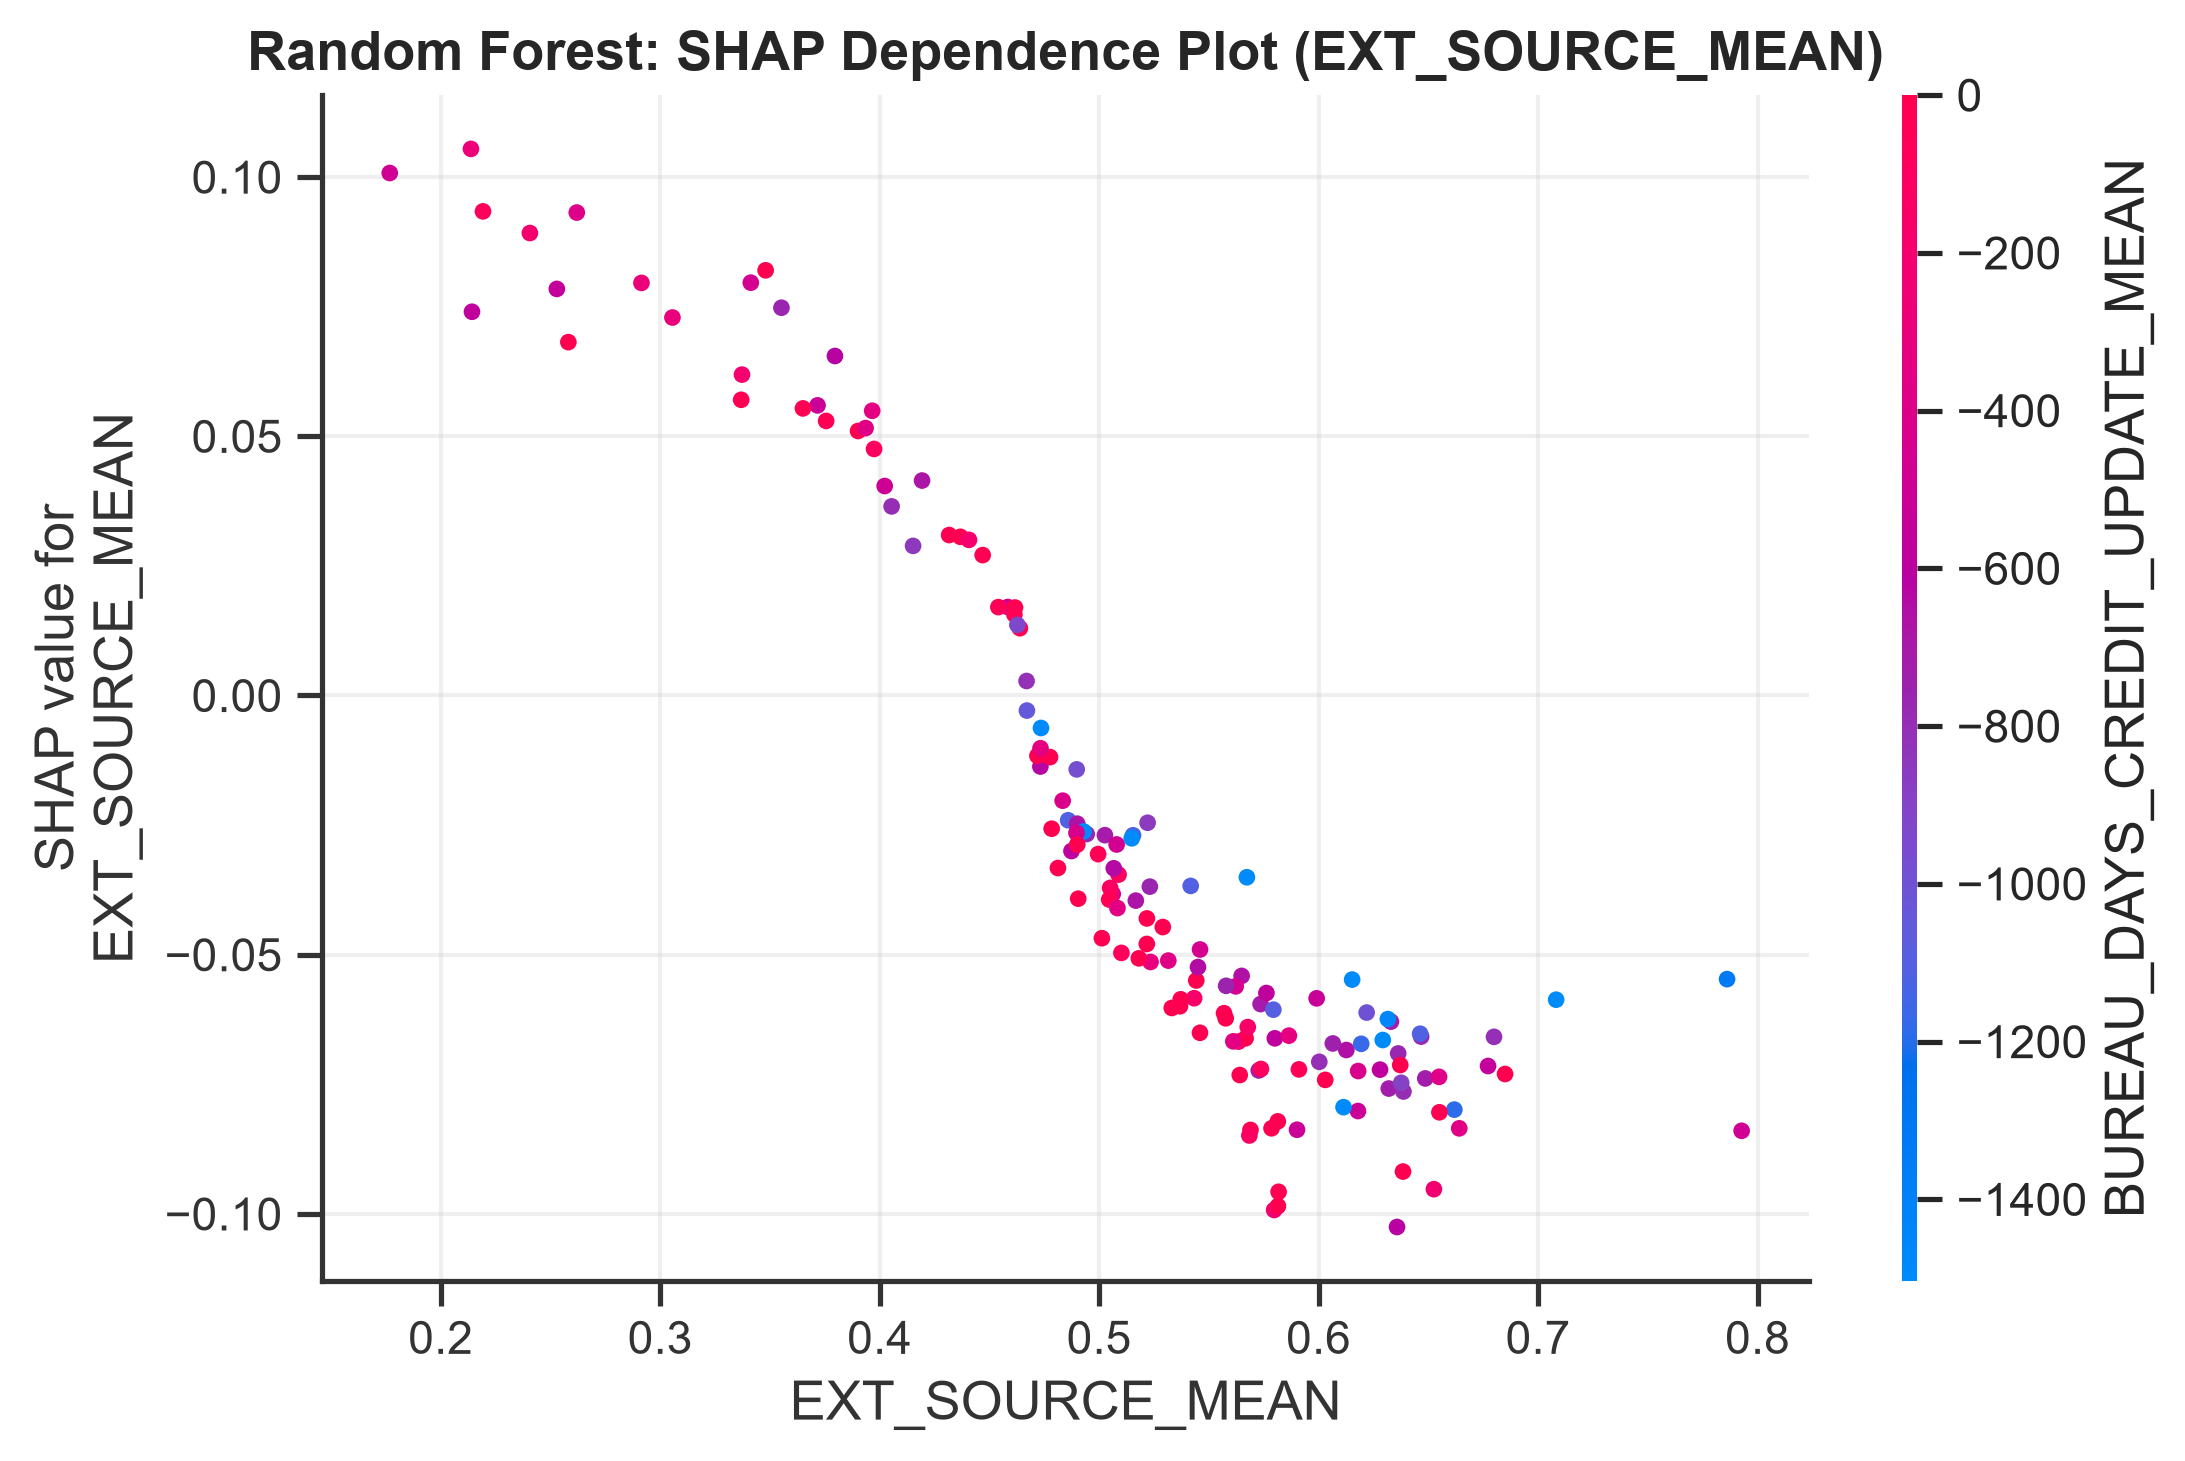

Low-risk applicant  - predicted default probability: 0.0528
High-risk applicant - predicted default probability: 0.7227


Figure saved to: ..\figures\10_rf_shap_local_low_risk.png


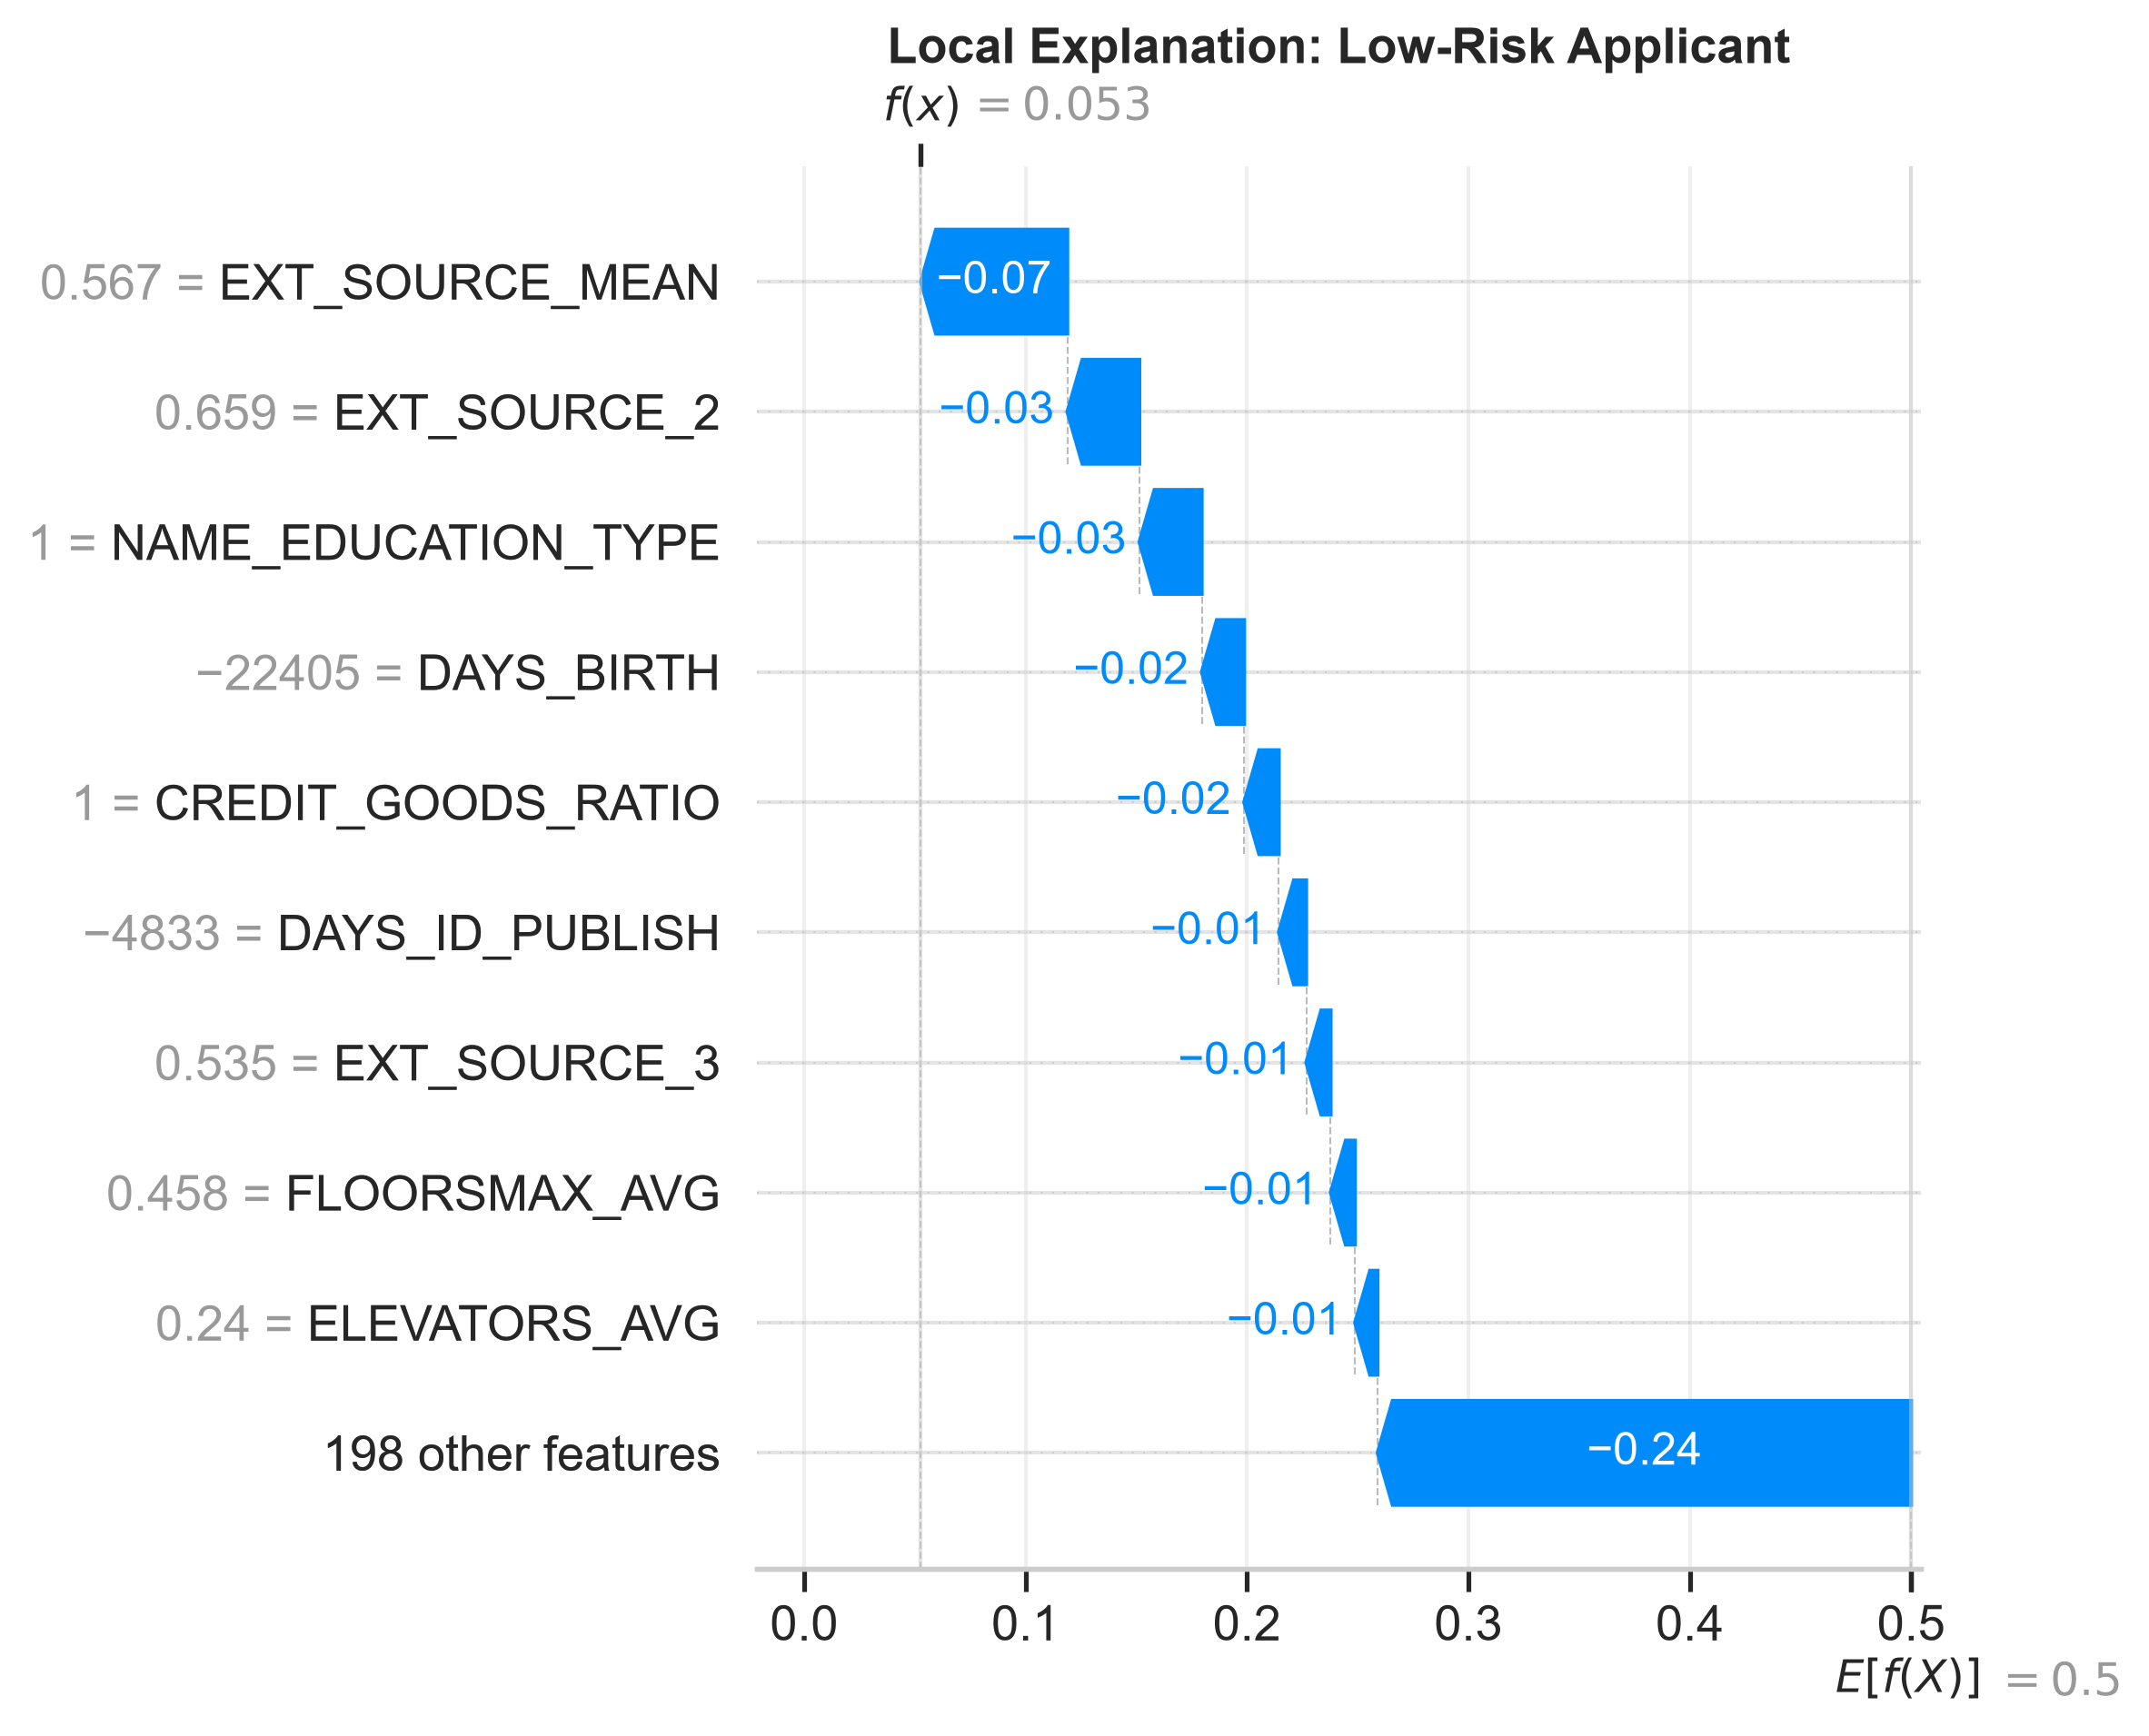

Figure saved to: ..\figures\10_rf_shap_local_high_risk.png


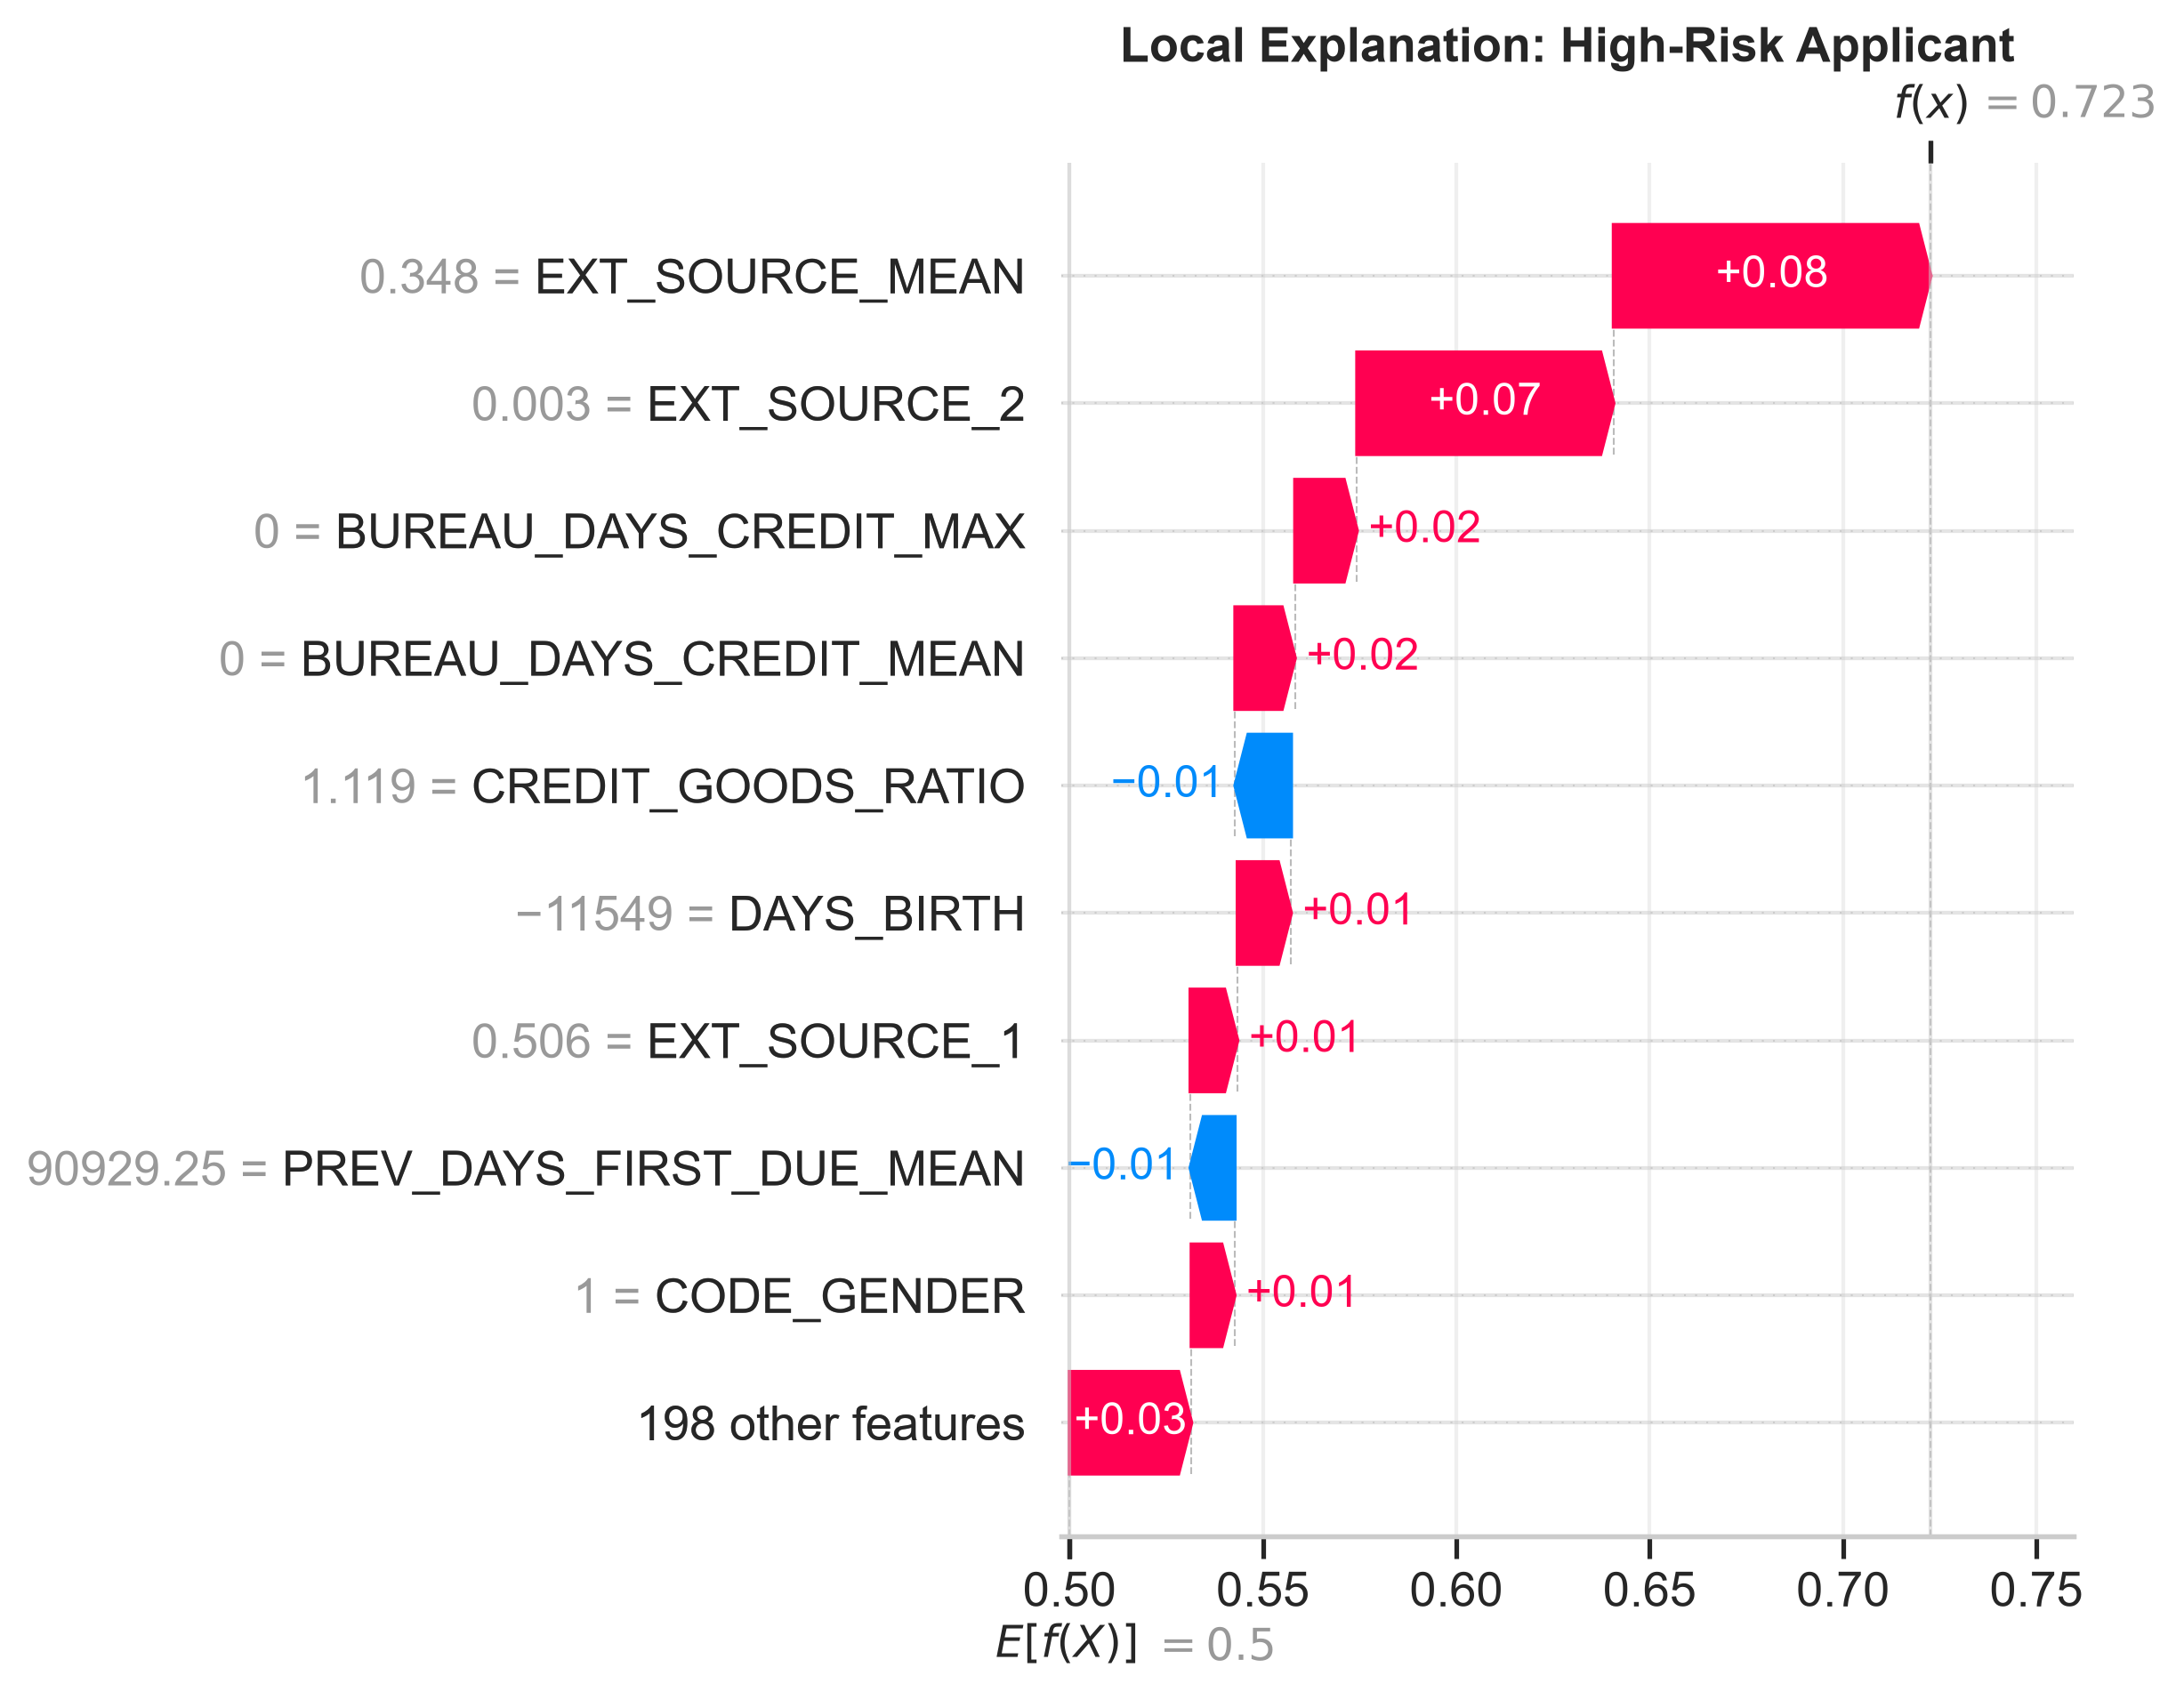

In [18]:
# ============================================================
# SHAP Dependence Plot & Local Explanations
# ============================================================

top_feature_name = mean_abs_shap.index[0]

shap.dependence_plot(top_feature_name, shap_values_default, shap_sample, show=False)
fig = plt.gcf()
plt.title(f"Random Forest: SHAP Dependence Plot ({top_feature_name})")
plt.tight_layout()
pu.save_fig(fig, "10_rf_shap_dependence")
plt.show()

predicted_prob_shap_sample = rf_model_shap.predict_proba(shap_sample)[:, 1]
low_risk_idx = int(np.argmin(predicted_prob_shap_sample))
high_risk_idx = int(np.argmax(predicted_prob_shap_sample))

print(f"Low-risk applicant  - predicted default probability: {predicted_prob_shap_sample[low_risk_idx]:.4f}")
print(f"High-risk applicant - predicted default probability: {predicted_prob_shap_sample[high_risk_idx]:.4f}")

# Use the Explanation-object API for clean waterfall plots (handles multi-class base values internally)
explanation_full = explainer(shap_sample, check_additivity=False)
explanation = explanation_full[..., 1] if explanation_full.values.ndim == 3 else explanation_full

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(explanation[low_risk_idx], show=False)
plt.title("Local Explanation: Low-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "10_rf_shap_local_low_risk")
plt.show()

fig = plt.figure(figsize=(9, 6))
shap.plots.waterfall(explanation[high_risk_idx], show=False)
plt.title("Local Explanation: High-Risk Applicant")
plt.tight_layout()
pu.save_fig(fig, "10_rf_shap_local_high_risk")
plt.show()

### Business Interpretation: SHAP Explainability

Averaging over hundreds of trees typically produces a smoother, more monotonic
dependence plot than the single Decision Tree's step function (Notebook 07) for the
same top feature — direct visual evidence that ensembling reduces the variance/noise in
the learned risk relationship, which should translate into more stable, defensible
score assignments for applicants near a decision boundary (a small change in an
applicant's `EXT_SOURCE_MEAN`, for example, should not flip their entire risk category).
The global feature ranking here should be compared feature-by-feature against Notebook
07's tree and Notebooks 11-12's boosted trees in Notebook 15: substantial agreement on
the top 5-10 features across all four tree-based models is strong evidence that the
credit-risk drivers identified are genuine signal rather than an artifact of one
particular algorithm, which materially strengthens the paper's claims about which
applicant characteristics actually drive default risk.